In [ ]:

from google.colab import drive

# Conectar Google Drive con Google Colab
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path
import pandas as pd

# Ruta principal del proyecto
DATA_PATH = Path(
    "/content/drive/MyDrive/DatosDeforestacion"
)

# Verificar que la carpeta exista
if DATA_PATH.exists():
    print("Carpeta encontrada correctamente.")
    print("\nArchivos disponibles:")

    for archivo in sorted(DATA_PATH.iterdir()):
        print("-", archivo.name)
else:
    print("ERROR: No se encontró la carpeta.")


Carpeta encontrada correctamente.

Archivos disponibles:
- BOL - Subnational 2 carbon data.csv
- BOL - Subnational 2 drivers.csv
- BOL - Subnational 2 primary drivers.csv
- BOL - Subnational 2 primary loss.csv
- BOL - Subnational 2 tree cover loss.csv


In [ ]:

# Archivos originales
archivos = {
    "carbon": "BOL - Subnational 2 carbon data.csv",
    "tree_cover": "BOL - Subnational 2 tree cover loss.csv",
    "drivers": "BOL - Subnational 2 drivers.csv",
    "primary_drivers": "BOL - Subnational 2 primary drivers.csv",
    "primary_loss": "BOL - Subnational 2 primary loss.csv"
}

# Diccionario donde guardaremos los DataFrames
datasets = {}

for nombre, archivo in archivos.items():

    ruta = DATA_PATH / archivo

    # Comprobar que el archivo exista
    if not ruta.is_file():
        raise FileNotFoundError(
            f"No se encontró el archivo: {ruta}"
        )

    # Cargar archivo CSV sin modificar sus valores
    datasets[nombre] = pd.read_csv(ruta)

    print(f"{nombre}: cargado correctamente")

print("\nTodos los datasets fueron cargados.")


carbon: cargado correctamente
tree_cover: cargado correctamente
drivers: cargado correctamente
primary_drivers: cargado correctamente
primary_loss: cargado correctamente

Todos los datasets fueron cargados.


In [ ]:

# Mostrar dimensiones de cada dataset
for nombre, df in datasets.items():

    print(f"\nDataset: {nombre}")
    print(f"Filas: {df.shape[0]}")
    print(f"Columnas: {df.shape[1]}")

# Mostrar las primeras cinco filas
# del dataset Tree Cover Loss
display(datasets["tree_cover"].head())



Dataset: carbon
Filas: 8400
Columnas: 12

Dataset: tree_cover
Filas: 22400
Columnas: 9

Dataset: drivers
Filas: 8351
Columnas: 7

Dataset: primary_drivers
Filas: 6506
Columnas: 7

Dataset: primary_loss
Filas: 1296
Columnas: 6


,country,subnational1,subnational2,threshold,area_ha,extent_2000_ha,extent_2010_ha,year,tc_loss_ha
0,Bolivia,Beni,Cercado,0,1068747,1068747,1068747,2001,583
1,Bolivia,Beni,Cercado,10,1068747,666418,666874,2001,565
2,Bolivia,Beni,Cercado,15,1068747,650356,660609,2001,562
3,Bolivia,Beni,Cercado,20,1068747,631921,650082,2001,559
4,Bolivia,Beni,Cercado,25,1068747,615948,633092,2001,556


## 1. Auditoría inicial de calidad de datos

### Objetivo

Evaluar el estado original de los cinco datasets de deforestación en Bolivia antes de realizar cualquier proceso de limpieza o transformación.

En esta etapa se analizarán:

- Cantidad de registros y columnas por dataset.
- Presencia de valores nulos.
- Existencia de filas completamente duplicadas.

**Metodología:** Utilizaremos la librería pandas para construir un reporte inicial de calidad de datos. Esta evaluación será nuestra línea base (*baseline*), que permitirá comparar los resultados obtenidos después de aplicar el pipeline de limpieza.

**Importante:** Este procedimiento es únicamente exploratorio. No se eliminarán, modificarán ni imputarán registros.

In [ ]:

# 1.1 Auditoría inicial de calidad

reporte_calidad = []

for nombre, df in datasets.items():

    # Dimensiones
    filas, columnas = df.shape

    # Contar valores nulos
    nulos = df.isna().sum().sum()

    # Contar filas exactamente duplicadas
    duplicados = df.duplicated().sum()

    reporte_calidad.append({
        "Dataset": nombre,
        "Filas": filas,
        "Columnas": columnas,
        "Valores nulos": nulos,
        "Filas duplicadas": duplicados
    })

# Convertir resultados en una tabla
df_reporte = pd.DataFrame(reporte_calidad)

display(df_reporte)


,Dataset,Filas,Columnas,Valores nulos,Filas duplicadas
0,carbon,8400,12,0,0
1,tree_cover,22400,9,0,0
2,drivers,8351,7,0,0
3,primary_drivers,6506,7,0,0
4,primary_loss,1296,6,0,0


### 1.2. Análisis de cobertura de los datasets

**Objetivo:** Identificar la cobertura temporal, geográfica y los umbrales de densidad arbórea disponibles en cada dataset.

**Metodología:**

Se analizarán las columnas `year`, `threshold`, `subnational1` y `subnational2` para determinar el periodo disponible, los umbrales registrados y la cantidad de unidades geográficas distintas.

Este análisis permitirá identificar diferencias estructurales entre las fuentes antes de integrarlas.

**Consideración:** La ausencia de una región, año o umbral en un dataset no implica automáticamente un error. Puede deberse a diferencias metodológicas o de cobertura de la fuente original.

No se realizarán modificaciones sobre los datos originales.

In [ ]:

# 1.2 Análisis de cobertura de los datasets

perfil_cobertura = []

for nombre, df in datasets.items():

    # Identificar rango temporal
    anio_inicio = df["year"].min()
    anio_fin = df["year"].max()

    # Identificar umbrales disponibles
    umbrales = sorted(df["threshold"].unique())

    # Contar unidades geográficas únicas
    unidades = df[
        ["subnational1", "subnational2"]
    ].drop_duplicates().shape[0]

    # Registrar información
    perfil_cobertura.append({
        "Dataset": nombre,
        "Año inicial": anio_inicio,
        "Año final": anio_fin,
        "Umbrales": str(umbrales),
        "Unidades geográficas": unidades
    })

# Crear reporte
df_cobertura = pd.DataFrame(perfil_cobertura)

display(df_cobertura)


,Dataset,Año inicial,Año final,Umbrales,Unidades geográficas
0,carbon,2001,2025,"[np.int64(30), np.int64(50), np.int64(75)]",112
1,tree_cover,2001,2025,"[np.int64(0), np.int64(10), np.int64(15), np.i...",112
2,drivers,2001,2025,[np.int64(30)],78
3,primary_drivers,2002,2025,[np.int64(30)],54
4,primary_loss,2002,2025,[np.int64(30)],54


### 1.3. Auditoría de correspondencia geográfica

**Objetivo:** Identificar qué unidades geográficas están presentes en los datasets `tree_cover` y `primary_loss`, y detectar diferencias de cobertura entre ambas fuentes.

**Metodología:**

Se utilizarán las columnas `country`, `subnational1` y `subnational2` como claves geográficas compuestas.

Primero se obtendrán las combinaciones geográficas únicas de cada dataset. Posteriormente se realizará una unión externa (*FULL OUTER JOIN*) para clasificar las unidades según su presencia en ambas fuentes.

Finalmente, se generará un reporte de correspondencia por departamento.

**Criterio de calidad:** Las diferencias de cobertura se registrarán como hallazgos de integración y no serán corregidas automáticamente mediante eliminación o imputación.

Esta auditoría no modifica los datasets originales.

In [ ]:

# 1.3 Auditoría geográfica

# Definir claves geográficas
claves_geo = [
    "country",
    "subnational1",
    "subnational2"
]

# Obtener unidades geográficas únicas
geo_tree = (
    datasets["tree_cover"][claves_geo]
    .drop_duplicates()
)

geo_primary = (
    datasets["primary_loss"][claves_geo]
    .drop_duplicates()
)

# Comparar ambas fuentes
auditoria_geo = pd.merge(
    geo_tree,
    geo_primary,
    on=claves_geo,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

# Mostrar resultados generales
print("Correspondencia geográfica:")
print(auditoria_geo["_merge"].value_counts())

# Reporte por departamento
reporte_geo = pd.crosstab(
    auditoria_geo["subnational1"],
    auditoria_geo["_merge"]
)

reporte_geo = reporte_geo.reindex(
    columns=["both", "left_only", "right_only"],
    fill_value=0
)

reporte_geo = reporte_geo.rename(columns={
    "both": "En ambos",
    "left_only": "Solo Tree Cover",
    "right_only": "Solo Primary Loss"
})

print("\nCorrespondencia por departamento:")
display(reporte_geo)


Correspondencia geográfica:
_merge
left_only     58
both          54
right_only     0
Name: count, dtype: int64

Correspondencia por departamento:


_merge,En ambos,Solo Tree Cover,Solo Primary Loss
subnational1,,,
Beni,8,0,0
Chuquisaca,7,3,0
Cochabamba,4,12,0
La Paz,11,9,0
Oruro,0,16,0
Pando,5,0,0
Potosí,0,16,0
Santa Cruz,15,0,0
Tarija,4,2,0


### 1.4. Temporal and Threshold Coverage Audit

**Objective:** Evaluate temporal coverage and tree canopy density thresholds across the five original datasets.

**Methodology:**

The audit groups observations by year and canopy density threshold to identify differences in data availability between sources.

Two coverage matrices are generated:

- **Temporal coverage:** Number of records available for each dataset and year.
- **Threshold coverage:** Number of records associated with each canopy density threshold.

**Data Quality Considerations:**

Differences in coverage do not necessarily indicate data quality errors. Some datasets may follow different temporal ranges, geographic coverage, or measurement methodologies.

A zero in a coverage matrix indicates that no records were found for that combination. It does not indicate zero deforestation or zero carbon emissions.

No source records are modified during this audit.

In [ ]:

# Temporal coverage
year_coverage = pd.DataFrame({
    name: df.groupby("year").size()
    for name, df in datasets.items()
}).fillna(0).astype(int)

# Canopy density threshold coverage
threshold_coverage = pd.DataFrame({
    name: df.groupby("threshold").size()
    for name, df in datasets.items()
}).fillna(0).astype(int)

print("Temporal coverage by dataset:")
display(year_coverage)

print("Threshold coverage by dataset:")
display(threshold_coverage)


Temporal coverage by dataset:


,carbon,tree_cover,drivers,primary_drivers,primary_loss
year,,,,,
2001,336,896,349,0,0
2002,336,896,348,272,54
2003,336,896,332,263,54
2004,336,896,345,256,54
2005,336,896,334,267,54
2006,336,896,345,264,54
2007,336,896,333,263,54
2008,336,896,342,271,54
2009,336,896,351,271,54


Threshold coverage by dataset:


,carbon,tree_cover,drivers,primary_drivers,primary_loss
threshold,,,,,
0,0,2800,0,0,0
10,0,2800,0,0,0
15,0,2800,0,0,0
20,0,2800,0,0,0
25,0,2800,0,0,0
30,2800,2800,8351,6506,1296
50,2800,2800,0,0,0
75,2800,2800,0,0,0


### 1.5. Data Types, Valid Domains and Primary Key Audit

**Objective:** Validate the structural integrity of the original datasets by examining data types, expected value domains and composite key uniqueness.

**Methodology:**

- Verify that numerical fields are stored using numeric data types.
- Validate year ranges and canopy density thresholds according to each dataset's documented coverage.
- Identify duplicate composite keys based on the granularity of each dataset.
- Check for negative forest loss measurements.

**Data Quality Considerations:**

Exact duplicate rows and duplicate composite keys are different issues. Duplicate keys may indicate multiple observations representing the same logical entity.

Negative values must also be interpreted according to the meaning of each variable. For example, negative net carbon flux may be valid and should not automatically be treated as a data error.

**Expected outcome:** A structural quality report identifying potential violations without modifying source records.

In [ ]:

# 1.5 Structural data quality audit

rules = {
    "carbon": ((2001, 2025), {30, 50, 75}),
    "tree_cover": ((2001, 2025), {0, 10, 15, 20, 25, 30, 50, 75}),
    "drivers": ((2001, 2025), {30}),
    "primary_drivers": ((2002, 2025), {30}),
    "primary_loss": ((2002, 2025), {30})
}

base_keys = [
    "country", "subnational1",
    "subnational2", "threshold", "year"
]

categorical_columns = {
    "country", "subnational1", "subnational2", "driver"
}

audit_results = []

for name, df in datasets.items():
    year_range, valid_thresholds = rules[name]

    keys = base_keys.copy()
    if "driver" in df.columns:
        keys.append("driver")

    invalid_types = [
        col for col in df.columns
        if col not in categorical_columns
        and not pd.api.types.is_numeric_dtype(df[col])
    ]

    loss_column = (
        "primary_tc_loss_ha" if name == "primary_loss"
        else "tc_loss_ha" if "tc_loss_ha" in df.columns
        else None
    )

    negative_loss = (
        int((df[loss_column] < 0).sum())
        if loss_column else None
    )

    audit_results.append({
        "Dataset": name,
        "Invalid numeric types": len(invalid_types),
        "Invalid years": int(
            (~df["year"].between(*year_range)).sum()
        ),
        "Invalid thresholds": int(
            (~df["threshold"].isin(valid_thresholds)).sum()
        ),
        "Duplicate keys": int(df.duplicated(keys).sum()),
        "Negative forest loss": negative_loss
    })

structural_report = pd.DataFrame(audit_results)

display(structural_report)


,Dataset,Invalid numeric types,Invalid years,Invalid thresholds,Duplicate keys,Negative forest loss
0,carbon,0,0,0,0,NaN
1,tree_cover,0,0,0,0,0.0
2,drivers,0,0,0,0,0.0
3,primary_drivers,0,0,0,0,0.0
4,primary_loss,0,0,0,0,0.0


### 1.6. Numerical Consistency Validation

**Objective:** Evaluate the logical consistency of forest cover measurements in the original Tree Cover Loss dataset.

**Validation rules:**

1. Land area must be greater than zero.
2. Forest cover extent must be non-negative and must not exceed the corresponding land area.
3. Annual tree cover loss must be non-negative.
4. Annual tree cover loss must not exceed the total land area.
5. Geographic reference measurements should remain consistent across years for the same geographic unit and canopy threshold.

**Methodology:** Boolean conditions and grouped uniqueness checks are used to identify potentially inconsistent observations.

**Important:** Detected violations will be investigated before any correction. No records will be removed or modified during this audit.

In [ ]:

tree = datasets["tree_cover"]

validation_rules = {
    "Invalid land area": tree["area_ha"] <= 0,

    "Invalid extent 2000": (
        (tree["extent_2000_ha"] < 0) |
        (tree["extent_2000_ha"] > tree["area_ha"])
    ),

    "Invalid extent 2010": (
        (tree["extent_2010_ha"] < 0) |
        (tree["extent_2010_ha"] > tree["area_ha"])
    ),

    "Negative annual loss": tree["tc_loss_ha"] < 0,

    "Annual loss exceeds land area": (
        tree["tc_loss_ha"] > tree["area_ha"]
    )
}

consistency_report = pd.DataFrame([
    {
        "Validation rule": rule,
        "Violations": int(condition.sum())
    }
    for rule, condition in validation_rules.items()
])

display(consistency_report)

geo_threshold_keys = [
    "country", "subnational1",
    "subnational2", "threshold"
]

reference_columns = [
    "area_ha",
    "extent_2000_ha",
    "extent_2010_ha"
]

reference_variations = (
    tree.groupby(geo_threshold_keys)[reference_columns]
    .nunique()
    .gt(1)
    .sum()
)

print("Groups with inconsistent reference values:")
display(reference_variations.to_frame("Inconsistent groups"))


,Validation rule,Violations
0,Invalid land area,0
1,Invalid extent 2000,0
2,Invalid extent 2010,0
3,Negative annual loss,0
4,Annual loss exceeds land area,0


Groups with inconsistent reference values:


,Inconsistent groups
area_ha,0
extent_2000_ha,0
extent_2010_ha,0


### 1.7. Cross-Dataset Consistency Audit: Tree Cover Loss vs. Drivers

**Objective:** Evaluate the consistency between total annual tree cover loss and the sum of losses attributed to individual drivers.

**Methodology:**

1. Filter Tree Cover Loss records to the 30% canopy density threshold, matching the Drivers dataset.
2. Aggregate driver-related losses by country, geographic unit, threshold and year.
3. Merge both datasets using their shared composite keys.
4. Identify matching and unmatched observations.
5. Calculate numerical differences for matched observations.

**Data Quality Considerations:**

Differences between the two measurements do not automatically indicate errors. Potential explanations include differences in source methodology, spatial classification, aggregation or numerical precision.

Missing driver observations will not be replaced with zero.

**Expected outcome:** A cross-dataset reconciliation report documenting coverage differences and numerical discrepancies.

No original records will be modified.

In [ ]:

join_keys = [
    "country",
    "subnational1",
    "subnational2",
    "threshold",
    "year"
]

tree_totals = (
    datasets["tree_cover"]
    .loc[lambda df: df["threshold"] == 30,
         join_keys + ["tc_loss_ha"]]
    .rename(columns={"tc_loss_ha": "tree_loss_ha"})
)

driver_totals = (
    datasets["drivers"]
    .groupby(join_keys, as_index=False)
    .agg(drivers_sum_ha=("tc_loss_ha", "sum"))
)

comparison = tree_totals.merge(
    driver_totals,
    on=join_keys,
    how="outer",
    validate="one_to_one",
    indicator=True
)

matched = comparison.loc[
    comparison["_merge"] == "both"
].copy()

matched["difference_ha"] = (
    matched["drivers_sum_ha"] - matched["tree_loss_ha"]
)

unmatched = comparison.loc[
    comparison["_merge"] == "left_only"
]

report = pd.DataFrame({
    "Metric": [
        "Tree Cover observations",
        "Matched observations",
        "Only Tree Cover",
        "Only Drivers",
        "Exact numerical matches",
        "Different numerical values",
        "Unmatched with positive tree loss"
    ],
    "Count": [
        len(tree_totals),
        len(matched),
        len(unmatched),
        int((comparison["_merge"] == "right_only").sum()),
        int((matched["difference_ha"] == 0).sum()),
        int((matched["difference_ha"] != 0).sum()),
        int((unmatched["tree_loss_ha"] > 0).sum())
    ]
})

display(report)

print("Examples of numerical differences:")
display(
    matched.loc[
        matched["difference_ha"] != 0,
        [
            "subnational1", "subnational2", "year",
            "tree_loss_ha", "drivers_sum_ha", "difference_ha"
        ]
    ].head(10)
)


,Metric,Count
0,Tree Cover observations,2800
1,Matched observations,1636
2,Only Tree Cover,1164
3,Only Drivers,0
4,Exact numerical matches,204
5,Different numerical values,1432
6,Unmatched with positive tree loss,13


Examples of numerical differences:


,subnational1,subnational2,year,tree_loss_ha,drivers_sum_ha,difference_ha
0,Beni,Cercado,2001,552,544.0,-8.0
1,Beni,Cercado,2002,2000,1968.0,-32.0
2,Beni,Cercado,2003,825,816.0,-9.0
3,Beni,Cercado,2004,2172,2150.0,-22.0
4,Beni,Cercado,2005,4014,3978.0,-36.0
5,Beni,Cercado,2006,1539,1528.0,-11.0
6,Beni,Cercado,2007,1130,1122.0,-8.0
7,Beni,Cercado,2008,5698,5658.0,-40.0
8,Beni,Cercado,2009,894,887.0,-7.0
9,Beni,Cercado,2010,2820,2799.0,-21.0


### 1.8. Investigation of a Cross-Dataset Discrepancy

**Objective:** Investigate the difference between total tree cover loss and the sum of driver-attributed losses for Beni–Cercado in 2001.

**Methodology:**

Select records from both datasets using the same geographic location, year and canopy density threshold (30%).

Inspect the individual driver categories and calculate their total attributed loss.

**Data Quality Principle:** A numerical discrepancy does not automatically indicate an incorrect observation. Corrections require supporting evidence and methodological justification.

No source values will be modified.

In [ ]:

tree = datasets["tree_cover"]
drivers = datasets["drivers"]

tree_case = tree.loc[
    (tree["subnational1"] == "Beni") &
    (tree["subnational2"] == "Cercado") &
    (tree["year"] == 2001) &
    (tree["threshold"] == 30)
]

drivers_case = drivers.loc[
    (drivers["subnational1"] == "Beni") &
    (drivers["subnational2"] == "Cercado") &
    (drivers["year"] == 2001) &
    (drivers["threshold"] == 30)
]

display(drivers_case[["driver", "tc_loss_ha"]])

tree_loss = tree_case["tc_loss_ha"].sum()
drivers_loss = drivers_case["tc_loss_ha"].sum()

print(f"Tree Cover Loss: {tree_loss} ha")
print(f"Drivers total: {drivers_loss} ha")
print(f"Difference: {tree_loss - drivers_loss} ha")


,driver,tc_loss_ha
0,Logging,1
1,Other natural disturbances,77
2,Permanent agriculture,402
3,Settlements & Infrastructure,39
4,Shifting cultivation,19
5,Wildfire,6


Tree Cover Loss: 552 ha
Drivers total: 544 ha
Difference: 8 ha


### 1.8. Cross-Dataset Discrepancy Analysis

**Objective:** Quantify the direction and magnitude of numerical differences between Tree Cover Loss and driver-attributed forest loss.

**Methodology:**

- Classify matched observations according to whether driver-attributed loss is lower than, equal to, or higher than total tree cover loss.
- Calculate absolute and relative numerical differences.
- Identify unmatched observations with positive tree cover loss.

**Data Quality Considerations:**

Numerical differences are potential reconciliation issues, not automatically data errors.

Relative differences are calculated only when the reference Tree Cover Loss value is greater than zero.

**Expected outcome:** A descriptive report to support further investigation of cross-dataset consistency.

No original records will be modified.

In [ ]:

differences = matched["difference_ha"]

direction_report = pd.DataFrame({
    "Comparison": [
        "Drivers lower than Tree Cover",
        "Equal values",
        "Drivers higher than Tree Cover"
    ],
    "Records": [
        int((differences < 0).sum()),
        int((differences == 0).sum()),
        int((differences > 0).sum())
    ]
})

display(direction_report)

discrepancies = matched.loc[
    matched["difference_ha"] != 0
].copy()

discrepancies["absolute_difference_ha"] = (
    discrepancies["difference_ha"].abs()
)

discrepancies["relative_difference_pct"] = (
    discrepancies["absolute_difference_ha"]
    .div(discrepancies["tree_loss_ha"].replace(0, float("nan")))
    .mul(100)
)

print("Discrepancy magnitude:")
display(
    discrepancies[
        ["absolute_difference_ha", "relative_difference_pct"]
    ].describe().round(2)
)

positive_unmatched = comparison.loc[
    (comparison["_merge"] == "left_only") &
    (comparison["tree_loss_ha"] > 0),
    join_keys + ["tree_loss_ha"]
].copy()

print("Positive tree loss without matching drivers:")
display(
    positive_unmatched.sort_values(
        "tree_loss_ha", ascending=False
    )
)


,Comparison,Records
0,Drivers lower than Tree Cover,1418
1,Equal values,204
2,Drivers higher than Tree Cover,14


Discrepancy magnitude:


,absolute_difference_ha,relative_difference_pct
count,1432.00,1432.00
mean,17.09,9.38
std,26.43,21.52
min,1.00,0.00
25%,3.00,0.21
50%,9.00,1.01
75%,20.00,4.62
max,402.00,100.00


Positive tree loss without matching drivers:


,country,subnational1,subnational2,threshold,year,tree_loss_ha
345,Bolivia,Chuquisaca,Oropeza,30,2021,1
635,Bolivia,Cochabamba,Cercado,30,2011,1
931,Bolivia,La Paz,Camacho,30,2007,1
932,Bolivia,La Paz,Camacho,30,2008,1
1056,Bolivia,La Paz,Ingavi,30,2007,1
1059,Bolivia,La Paz,Ingavi,30,2010,1
1925,Bolivia,Potosí,Chayanta,30,2001,1
1929,Bolivia,Potosí,Chayanta,30,2005,1
1933,Bolivia,Potosí,Chayanta,30,2009,1
1969,Bolivia,Potosí,Chárcas,30,2020,1


### 1.9. Aggregated Reconciliation Analysis

**Objective:** Evaluate the magnitude of discrepancies between Tree Cover Loss and Drivers at the dataset and departmental levels.

**Methodology:**

Only observations successfully matched between both datasets are included.

The analysis calculates total forest loss, net differences and relative differences by department.

**Mathematical formulas**

**1. Net difference (hectares):**

$$
D_{ha} = \sum Drivers_{ha} - \sum TreeCover_{ha}
$$

**2. Relative net difference (%):**

$$
D_{\%} = \frac{D_{ha}}{\sum TreeCover_{ha}}\times100
$$

**3. Absolute difference for an individual observation:**

$$
D_{abs} = |Drivers_{ha}-TreeCover_{ha}|
$$

**Interpretation:**

A negative net difference indicates that aggregated driver-attributed loss is lower than the corresponding Tree Cover Loss measurement.

The relative difference of aggregated totals must not be confused with the arithmetic mean of individual relative differences.

**Data Quality Considerations:**

- The analysis excludes unmatched observations from both total measurements.
- Results should not be interpreted as independently verified forest loss.
- Differences do not automatically imply data errors.
- No source records are modified.

In [ ]:

department_report = (
    matched.groupby("subnational1", as_index=False)
    .agg(
        observations=("difference_ha", "size"),
        tree_loss_ha=("tree_loss_ha", "sum"),
        drivers_loss_ha=("drivers_sum_ha", "sum")
    )
)

department_report["net_difference_ha"] = (
    department_report["drivers_loss_ha"]
    - department_report["tree_loss_ha"]
)

department_report["relative_difference_pct"] = (
    department_report["net_difference_ha"]
    / department_report["tree_loss_ha"].replace(0, float("nan"))
    * 100
)

display(
    department_report.sort_values(
        "net_difference_ha"
    ).round(2)
)

total_tree = matched["tree_loss_ha"].sum()
total_drivers = matched["drivers_sum_ha"].sum()

net_difference = total_drivers - total_tree
relative_difference = net_difference / total_tree * 100

print(f"Tree Cover total: {total_tree:,.0f} ha")
print(f"Drivers total: {total_drivers:,.0f} ha")
print(f"Net difference: {net_difference:,.0f} ha")
print(f"Relative difference: {relative_difference:.2f}%")


,subnational1,observations,tree_loss_ha,drivers_loss_ha,net_difference_ha,relative_difference_pct
7,Santa Cruz,375,7355148,7347268.0,-7880.0,-0.11
0,Beni,200,1799194,1792955.0,-6239.0,-0.35
3,La Paz,320,465994,462292.0,-3702.0,-0.79
5,Pando,125,318107,316145.0,-1962.0,-0.62
1,Chuquisaca,228,90993,89315.0,-1678.0,-1.84
2,Cochabamba,222,321420,319920.0,-1500.0,-0.47
8,Tarija,145,192947,191489.0,-1458.0,-0.76
6,Potosí,19,66,39.0,-27.0,-40.91
4,Oruro,2,1,0.0,-1.0,-100.00


Tree Cover total: 10,543,870 ha
Drivers total: 10,519,423 ha
Net difference: -24,447 ha
Relative difference: -0.23%


#### Interpretation of Aggregated Reconciliation Results

The cross-dataset reconciliation identified the following results across 1,636 matched observations:

- **Total Tree Cover Loss:** 10,543,870 ha
- **Total Driver-Attributed Loss:** 10,519,423 ha
- **Net Difference:** -24,447 ha
- **Relative Net Difference:** -0.23%

**Mathematical interpretation**

The relative net difference is calculated as:

$$
D_{\%}=\frac{\sum Drivers-\sum TreeCover}{\sum TreeCover}\times100
$$

For the observed data:

$$
D_{\%}=\frac{10{,}519{,}423-10{,}543{,}870}{10{,}543{,}870}\times100
$$

$$
D_{\%}\approx -0.23\%
$$

The mean absolute relative discrepancy among the 1,432 observations with numerical differences is:

$$
MARE=\frac{1}{n}\sum_{i=1}^{n}\left|\frac{Drivers_i-TreeCover_i}{TreeCover_i}\right|\times100
$$

where \(n=1432\).

The resulting value is **9.38%**.

**Key Findings**

1. Driver-attributed loss is lower than total Tree Cover Loss in most matched observations.
2. Departmental differences vary substantially in absolute and relative terms.
3. Small reference values can produce large relative discrepancies.
4. The net relative difference of -0.23% must not be interpreted as a data quality score or proof of measurement accuracy.
5. Differences remain unresolved until their methodological causes can be established.

**Decision:** Preserve original measurements and document the discrepancies for further investigation.

### 1.10. Reconciliation Metrics and Data Quality Interpretation

**Objective:** Distinguish numerical reconciliation metrics from general data quality indicators.

**Methodology:**

Three complementary indicators are calculated:

**1. Matching coverage (%)**

Measures the proportion of Tree Cover observations with corresponding Drivers records.

$$
Coverage_{\%}=\frac{N_{matched}}{N_{tree}}\times100
$$

**2. Net relative difference (%)**

Measures the signed difference between aggregated values.

$$
NetGap_{\%}=\frac{\sum Drivers-\sum TreeCover}{\sum TreeCover}\times100
$$

**3. Absolute reconciliation gap (%)**

Measures the sum of absolute numerical discrepancies relative to the total Tree Cover Loss across matched observations.

$$
AbsoluteGap_{\%}=\frac{\sum_{i=1}^{n}|Drivers_i-TreeCover_i|}{\sum_{i=1}^{n}TreeCover_i}\times100
$$

**Interpretation:**

- Matching coverage measures data availability across sources.
- Net relative difference measures aggregate numerical disagreement and may hide offsetting discrepancies.
- Absolute reconciliation gap measures disagreement without cancellation of positive and negative differences.

**Important:** These metrics do not constitute an overall data quality or accuracy score. They describe different aspects of cross-dataset reconciliation.

Only matched observations are included in the numerical gap calculations. Source records remain unchanged.

In [ ]:

matched_count = len(matched)
tree_count = len(tree_totals)

matching_coverage = matched_count / tree_count * 100

total_tree = matched["tree_loss_ha"].sum()
total_drivers = matched["drivers_sum_ha"].sum()

net_gap_pct = (
    (total_drivers - total_tree) / total_tree * 100
)

absolute_gap_pct = (
    matched["difference_ha"].abs().sum()
    / total_tree * 100
)

reconciliation_metrics = pd.DataFrame({
    "Metric": [
        "Matching coverage (%)",
        "Net relative difference (%)",
        "Absolute reconciliation gap (%)"
    ],
    "Value": [
        matching_coverage,
        net_gap_pct,
        absolute_gap_pct
    ]
})

display(reconciliation_metrics.round(2))


,Metric,Value
0,Matching coverage (%),58.43
1,Net relative difference (%),-0.23
2,Absolute reconciliation gap (%),0.23


### 2.1. Safe Multi-Source Data Integration

**Objective:** Build a reproducible analytical dataset by integrating five forest-related sources using the 30% canopy density threshold.

**Methodology:**

1. Use Tree Cover Loss as the base dataset.
2. Aggregate driver-attributed losses by geographic unit, year and threshold.
3. Integrate Carbon Data, Primary Forest Loss and both Drivers datasets using validated composite keys.
4. Preserve missing measurements as null values.
5. Track source availability and verify that joins do not multiply records.

**Composite key:**

`country + subnational1 + subnational2 + threshold + year`

**Reconciliation formula:**

$$
D_{ha}=\sum Drivers_{ha}-TreeCoverLoss_{ha}
$$

**Data Quality Rules:**

- Original source files remain unchanged.
- No automatic imputation is performed.
- Missing observations are not interpreted as zero.
- Duplicate keys and unexpected row multiplication are treated as integration failures.

**Expected outcome:** A validated integrated CSV suitable for further quality controls and exploratory analysis.

In [ ]:

from pathlib import Path

keys = [
    "country", "subnational1", "subnational2",
    "threshold", "year"
]

master = (
    datasets["tree_cover"]
    .loc[lambda df: df["threshold"] == 30]
    .rename(columns={"tc_loss_ha": "tree_loss_ha"})
    .copy()
)

carbon = datasets["carbon"].query("threshold == 30").copy()
primary_loss = datasets["primary_loss"].copy()

drivers = (
    datasets["drivers"]
    .groupby(keys, as_index=False)["tc_loss_ha"]
    .sum()
    .rename(columns={"tc_loss_ha": "drivers_sum_ha"})
)

primary_drivers = (
    datasets["primary_drivers"]
    .groupby(keys, as_index=False)["tc_loss_ha"]
    .sum()
    .rename(columns={"tc_loss_ha": "primary_drivers_sum_ha"})
)

sources = {
    "carbon": carbon,
    "primary_loss": primary_loss,
    "drivers": drivers,
    "primary_drivers": primary_drivers
}

original_rows = len(master)

for name, source in sources.items():
    master = master.merge(
        source,
        on=keys,
        how="left",
        validate="one_to_one",
        indicator=True
    )

    master[f"has_{name}"] = master.pop("_merge").eq("both")

    assert len(master) == original_rows, (
        f"Unexpected row count after merging {name}"
    )

assert not master.duplicated(keys).any()
assert master.loc[
    master["year"] == 2001, "primary_tc_loss_ha"
].isna().all()

output_path = DATA_PATH / "processed"
output_path.mkdir(parents=True, exist_ok=True)

master.to_csv(
    output_path / "deforestation_integrated_threshold30_v2.csv",
    index=False
)

print(f"Integrated dataset: {master.shape}")
print("\nSource coverage:")

for name in sources:
    print(f"{name}: {master[f'has_{name}'].sum()} matches")

display(master.head())


Integrated dataset: (2800, 23)

Source coverage:
carbon: 2800 matches
primary_loss: 1296 matches
drivers: 1636 matches
primary_drivers: 1272 matches


,country,subnational1,subnational2,threshold,area_ha,extent_2000_ha,extent_2010_ha,year,tree_loss_ha,umd_tree_cover_extent_2000__ha,...,gfw_forest_carbon_gross_removals__Mg_CO2_yr-1,gfw_forest_carbon_net_flux__Mg_CO2e_yr-1,gfw_forest_carbon_gross_emissions__Mg_CO2e,has_carbon,primary_tc_loss_ha,has_primary_loss,drivers_sum_ha,has_drivers,primary_drivers_sum_ha,has_primary_drivers
0,Bolivia,Beni,Cercado,30,1068747,604362,607680,2001,552,604362,...,2041008,-380646,162876,True,NaN,False,544.0,True,NaN,False
1,Bolivia,Beni,General José Ballivián,30,3271607,1992873,1984358,2001,5360,1992873,...,5774137,1694889,3059475,True,NaN,False,5337.0,True,NaN,False
2,Bolivia,Beni,Iténez,30,3729683,2426263,2475517,2001,1261,2426263,...,7104887,-3855187,452174,True,NaN,False,1229.0,True,NaN,False
3,Bolivia,Beni,Mamoré,30,1871640,673232,686749,2001,612,673232,...,2496676,-1772002,218607,True,NaN,False,587.0,True,NaN,False
4,Bolivia,Beni,Marbán,30,1679222,1120302,1108920,2001,1185,1120302,...,3959019,-460494,470098,True,NaN,False,1164.0,True,NaN,False


### 2.2. Integrated Dataset Quality Validation

**Objective:** Validate the structural integrity, source coverage and missing-value consistency of the integrated dataset.

**Methodology:**

The validation process checks:

- Preservation of the expected number of records.
- Uniqueness of composite keys.
- Consistency of canopy density thresholds and years.
- Preservation of missing primary forest measurements for 2001.
- Consistency between source availability flags and integrated measurements.

**Mathematical formulas**

**1. Row preservation**

$$
N_{integrated}=N_{base}
$$

**2. Duplicate key count**

$$
D=\sum_{i=1}^{N}I(Key_i\text{ is repeated})
$$

**3. Source coverage**

$$
Coverage_{\%}=\frac{N_{matched}}{N_{integrated}}\times100
$$

Where \(I\) is an indicator function and \(N_{matched}\) represents records with a corresponding source observation.

**Expected outcome:** A reproducible validation report identifying whether the integration satisfies the defined structural rules.

**Data Quality Principle:** Passing these checks does not guarantee measurement accuracy or methodological consistency. Original observations are preserved without automatic corrections.

In [ ]:

source_metrics = {
    "carbon": "umd_tree_cover_extent_2000__ha",
    "primary_loss": "primary_tc_loss_ha",
    "drivers": "drivers_sum_ha",
    "primary_drivers": "primary_drivers_sum_ha"
}

checks = {
    "Row count preserved": len(master) == 2800,
    "Unique composite keys": not master.duplicated(keys).any(),
    "Valid threshold": master["threshold"].eq(30).all(),
    "Valid year range": master["year"].between(2001, 2025).all(),
    "Tree loss available": master["tree_loss_ha"].notna().all(),
    "No primary loss values in 2001": master.loc[
        master["year"] == 2001, "primary_tc_loss_ha"
    ].isna().all()
}

for name, metric in source_metrics.items():
    flag = master[f"has_{name}"]
    checks[f"{name} availability consistency"] = (
        master.loc[flag, metric].notna().all()
        and master.loc[~flag, metric].isna().all()
    )

validation_report = pd.DataFrame([
    {"Validation": name, "Passed": bool(result)}
    for name, result in checks.items()
])

coverage_report = pd.DataFrame([
    {
        "Source": name,
        "Matched": int(master[f"has_{name}"].sum()),
        "Unmatched": int((~master[f"has_{name}"]).sum()),
        "Coverage (%)": round(
            master[f"has_{name}"].mean() * 100, 2
        )
    }
    for name in source_metrics
])

display(validation_report)
display(coverage_report)

reports_path = DATA_PATH / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

validation_report.to_csv(
    reports_path / "integration_validation_v2.csv",
    index=False
)

coverage_report.to_csv(
    reports_path / "source_coverage_v2.csv",
    index=False
)

print(
    f"Validations passed: "
    f"{validation_report['Passed'].sum()}/{len(validation_report)}"
)


,Validation,Passed
0,Row count preserved,True
1,Unique composite keys,True
2,Valid threshold,True
3,Valid year range,True
4,Tree loss available,True
5,No primary loss values in 2001,True
6,carbon availability consistency,True
7,primary_loss availability consistency,True
8,drivers availability consistency,True
9,primary_drivers availability consistency,True


,Source,Matched,Unmatched,Coverage (%)
0,carbon,2800,0,100.00
1,primary_loss,1296,1504,46.29
2,drivers,1636,1164,58.43
3,primary_drivers,1272,1528,45.43


Validations passed: 10/10


### 2.3. Pipeline Reproducibility Test

**Objective:** Verify that the integrated dataset can be reconstructed directly from the five original CSV files.

**Methodology:**

A reusable Python function loads the original sources, performs validated joins and checks the structural integrity of the resulting dataset.

The reconstructed dataset is compared against the previously validated integration.

**Validation criteria:**

$$
N_{reconstructed}=N_{original\ integration}
$$

Additionally, all columns, values, data types and record order must match the reference integration.

**Expected outcome:** An independently reconstructed dataset containing 2,800 records and 23 columns, with identical results to the original integration.

**Important:** Reproducibility confirms that the same processing logic generates the same output. It does not independently establish the scientific accuracy of the source measurements.

In [ ]:

from pathlib import Path
import pandas as pd

FILES = {
    "carbon": "BOL - Subnational 2 carbon data.csv",
    "tree_cover": "BOL - Subnational 2 tree cover loss.csv",
    "drivers": "BOL - Subnational 2 drivers.csv",
    "primary_drivers": "BOL - Subnational 2 primary drivers.csv",
    "primary_loss": "BOL - Subnational 2 primary loss.csv"
}

KEYS = [
    "country", "subnational1", "subnational2",
    "threshold", "year"
]

def build_dataset_from_csv(data_path: Path) -> pd.DataFrame:
    """Rebuild and validate the integrated forest dataset."""

    raw = {
        name: pd.read_csv(data_path / filename)
        for name, filename in FILES.items()
    }

    base = (
        raw["tree_cover"]
        .loc[lambda df: df["threshold"].eq(30)]
        .rename(columns={"tc_loss_ha": "tree_loss_ha"})
        .copy()
    )

    sources = {
        "carbon": raw["carbon"].query("threshold == 30").copy(),
        "primary_loss": raw["primary_loss"].copy(),
        "drivers": (
            raw["drivers"]
            .groupby(KEYS, as_index=False)["tc_loss_ha"]
            .sum()
            .rename(columns={"tc_loss_ha": "drivers_sum_ha"})
        ),
        "primary_drivers": (
            raw["primary_drivers"]
            .groupby(KEYS, as_index=False)["tc_loss_ha"]
            .sum()
            .rename(columns={"tc_loss_ha": "primary_drivers_sum_ha"})
        )
    }

    result = base

    for name, source in sources.items():
        result = result.merge(
            source,
            on=KEYS,
            how="left",
            validate="one_to_one",
            indicator=True
        )
        result[f"has_{name}"] = result.pop("_merge").eq("both")

    if len(result) != len(base) or result.duplicated(KEYS).any():
        raise ValueError("Invalid integration structure")

    if not result.loc[
        result["year"].eq(2001), "primary_tc_loss_ha"
    ].isna().all():
        raise ValueError("Invalid primary loss temporal coverage")

    return result


rebuilt = build_dataset_from_csv(DATA_PATH)

pd.testing.assert_frame_equal(
    rebuilt.reset_index(drop=True),
    master.reset_index(drop=True)
)

print("Reproducibility test: PASSED")
print(f"Rows: {len(rebuilt):,}")
print(f"Columns: {rebuilt.shape[1]}")
print("All values and data types match the reference dataset.")


Reproducibility test: PASSED
Rows: 2,800
Columns: 23
All values and data types match the reference dataset.


### 3.1. Exploratory Data Analysis and IQR Outlier Detection

**Objective:** Analyze numerical distributions and identify potential outliers across the five original datasets.

**Methodology:**

The Interquartile Range (IQR) method is used to identify observations located beyond the expected statistical range.

**Mathematical formulas:**

$$
IQR=Q_3-Q_1
$$

$$
Lower=Q_1-1.5(IQR)
$$

$$
Upper=Q_3+1.5(IQR)
$$

Observations outside these boundaries are flagged as potential outliers.

For visualization, a logarithmic transformation is applied:

$$
x'=\ln(1+x)
$$

This transformation reduces visual skewness while preserving the original values in the source datasets.

**Data Quality Considerations:**

Statistical outliers are not necessarily data errors. Extreme forest loss or carbon emission measurements may represent real environmental events.

**Expected outcome:** Five distribution charts and a statistical outlier summary.

No original observations will be removed, capped, or modified.

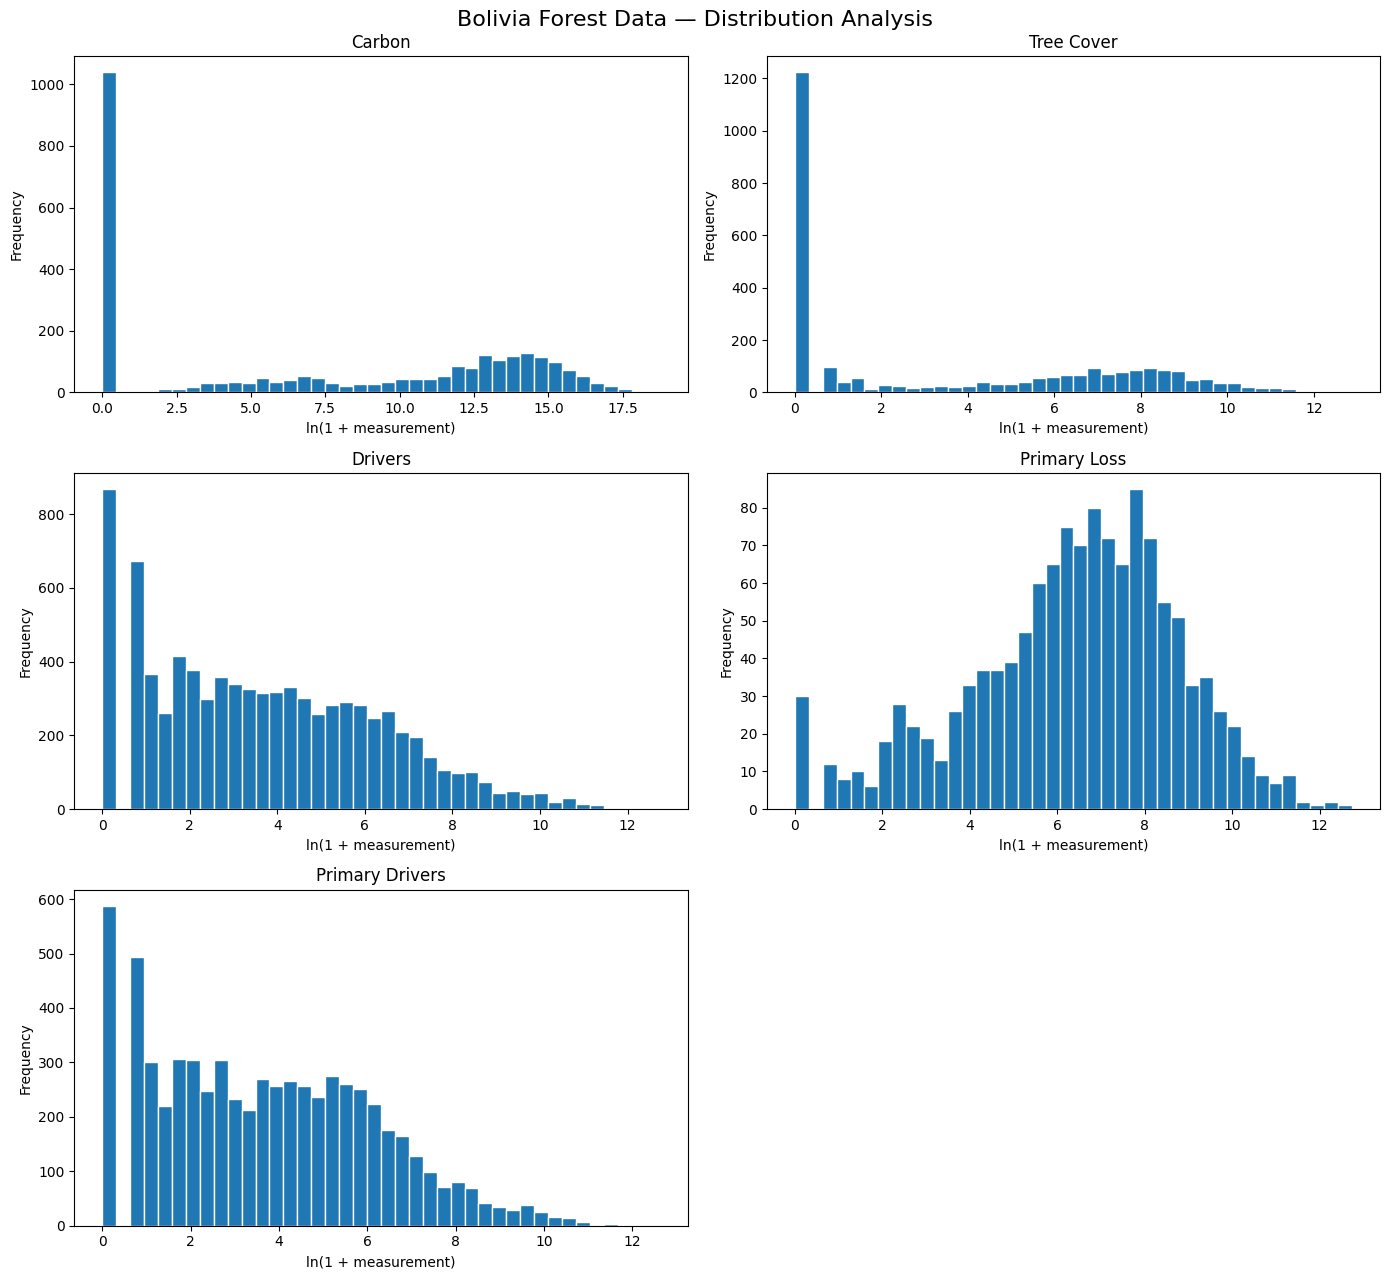

,Dataset,Observations,Q1,Q3,IQR,Outliers,Outliers (%)
0,carbon,2800,0.0,629415.25,629415.25,476,17.00
1,tree_cover,2800,0.0,1379.75,1379.75,473,16.89
2,drivers,8351,3.0,273.00,270.00,1298,15.54
3,primary_loss,1296,150.0,3040.75,2890.75,165,12.73
4,primary_drivers,6506,4.0,240.75,236.75,944,14.51


In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

figures_path = DATA_PATH / "figures"
figures_path.mkdir(parents=True, exist_ok=True)

eda_variables = {
    "carbon": "gfw_forest_carbon_gross_emissions__Mg_CO2e",
    "tree_cover": "tc_loss_ha",
    "drivers": "tc_loss_ha",
    "primary_loss": "primary_tc_loss_ha",
    "primary_drivers": "tc_loss_ha"
}

iqr_results = []

fig, axes = plt.subplots(3, 2, figsize=(14, 13))
axes = axes.flatten()

for i, (name, column) in enumerate(eda_variables.items()):
    df = datasets[name]
    values = df.loc[df["threshold"] == 30, column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (values < lower) | (values > upper)

    iqr_results.append({
        "Dataset": name,
        "Observations": len(values),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Outliers": int(outliers.sum()),
        "Outliers (%)": round(outliers.mean() * 100, 2)
    })

    axes[i].hist(np.log1p(values), bins=40, edgecolor="white")
    axes[i].set_title(name.replace("_", " ").title())
    axes[i].set_xlabel("ln(1 + measurement)")
    axes[i].set_ylabel("Frequency")

axes[-1].axis("off")

plt.suptitle(
    "Bolivia Forest Data — Distribution Analysis",
    fontsize=16
)
plt.tight_layout()
plt.savefig(
    figures_path / "01_distribution_analysis.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

iqr_report = pd.DataFrame(iqr_results)
display(iqr_report)


### 3.2. OLS vs. RANSAC Regression Sensitivity Analysis

**Objective:** Compare ordinary linear regression with robust regression to evaluate the influence of extreme observations.

**Methodology:**

The analysis uses 2024 carbon emission measurements and forest cover extent from 2000, selecting the 30% canopy density threshold.

**Ordinary Least Squares (OLS):**

$$
\hat{y}=\beta_0+\beta_1x
$$

OLS minimizes the sum of squared residuals:

$$
\min_{\beta_0,\beta_1}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

**RANSAC (Random Sample Consensus):**

RANSAC repeatedly estimates a regression model from subsets of observations and identifies points consistent with the fitted model under a residual threshold.

**Variables:**

- X: Forest cover extent in 2000 (ha).
- Y: Annual gross forest carbon emissions in 2024 (Mg CO2e).

**Data Quality Considerations:**

- RANSAC outliers are model-dependent classifications, not confirmed measurement errors.
- The analysis evaluates sensitivity, not causality.
- No observations will be deleted or replaced.

**Expected outcome:** A regression comparison chart and a summary of RANSAC inliers and outliers.

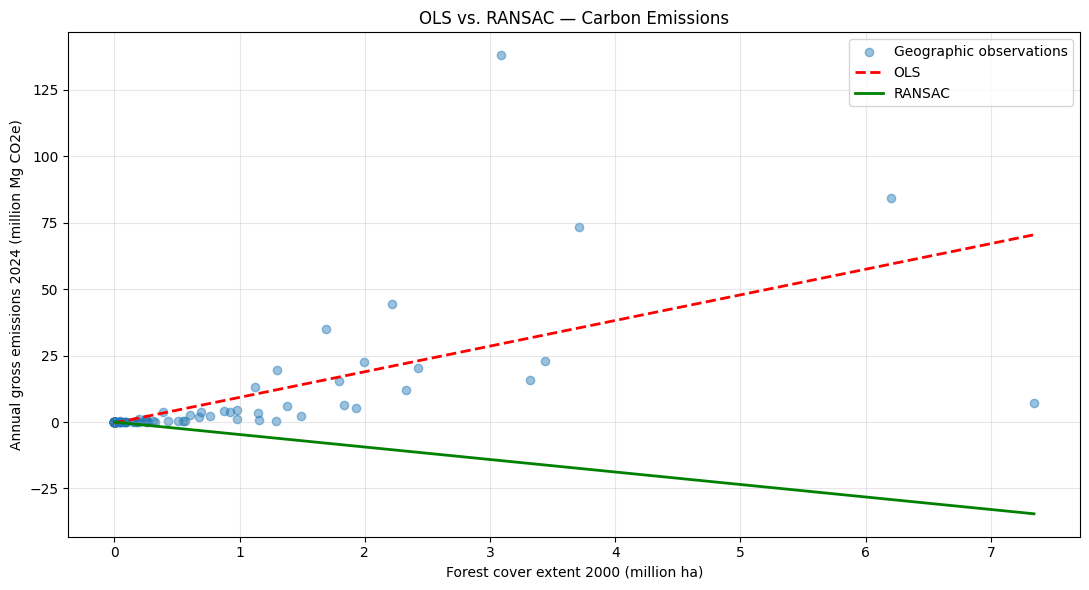

Observations: 112
OLS slope: 9.645
RANSAC slope: -4.7027
RANSAC inliers: 2
RANSAC outliers: 110


In [22]:

from sklearn.linear_model import LinearRegression, RANSACRegressor

carbon_2024 = datasets["carbon"].loc[
    (datasets["carbon"]["year"] == 2024) &
    (datasets["carbon"]["threshold"] == 30)
].copy()

x_column = "umd_tree_cover_extent_2000__ha"
y_column = "gfw_forest_carbon_gross_emissions__Mg_CO2e"

X = carbon_2024[[x_column]].to_numpy()
y = carbon_2024[y_column].to_numpy()

ols = LinearRegression().fit(X, y)

ransac = RANSACRegressor(
    estimator=LinearRegression(),
    min_samples=0.5,
    max_trials=500,
    random_state=42
).fit(X, y)

x_line = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

plt.figure(figsize=(11, 6))

plt.scatter(
    X / 1e6, y / 1e6,
    alpha=0.45, label="Geographic observations"
)

plt.plot(
    x_line / 1e6,
    ols.predict(x_line) / 1e6,
    "r--", linewidth=2, label="OLS"
)

plt.plot(
    x_line / 1e6,
    ransac.predict(x_line) / 1e6,
    "g-", linewidth=2, label="RANSAC"
)

plt.xlabel("Forest cover extent 2000 (million ha)")
plt.ylabel("Annual gross emissions 2024 (million Mg CO2e)")
plt.title("OLS vs. RANSAC — Carbon Emissions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_path / "02_ols_vs_ransac.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("Observations:", len(X))
print("OLS slope:", round(float(ols.coef_[0]), 4))
print(
    "RANSAC slope:",
    round(float(ransac.estimator_.coef_[0]), 4)
)
print("RANSAC inliers:", int(ransac.inlier_mask_.sum()))
print("RANSAC outliers:", int((~ransac.inlier_mask_).sum()))


### 3.3. Integrated Dataset — Temporal Trend Analysis

**Objective:** Explore annual trends in tree cover loss and gross forest carbon emissions using the integrated dataset.

**Methodology:**

Annual totals are calculated by aggregating observations across geographic units for the 30% canopy density threshold.

**Mathematical formula:**

$$
Total_y=\sum_{i=1}^{n_y}x_{i,y}
$$

Where:

- \(y\) represents the year.
- \(n_y\) is the number of geographic observations for that year.
- \(x_{i,y}\) is the measurement for geographic unit \(i\).

**Variables:**

- Annual tree cover loss (ha).
- Annual gross forest carbon emissions (Mg CO2e).

**Data Quality Considerations:**

Only annual measurement variables are aggregated across years. Static forest extent measurements and long-period annual averages are excluded from temporal summation.

The charts show separate trends and do not establish a causal relationship between the indicators.

**Expected outcome:** Two annual time-series charts covering 2001–2025.

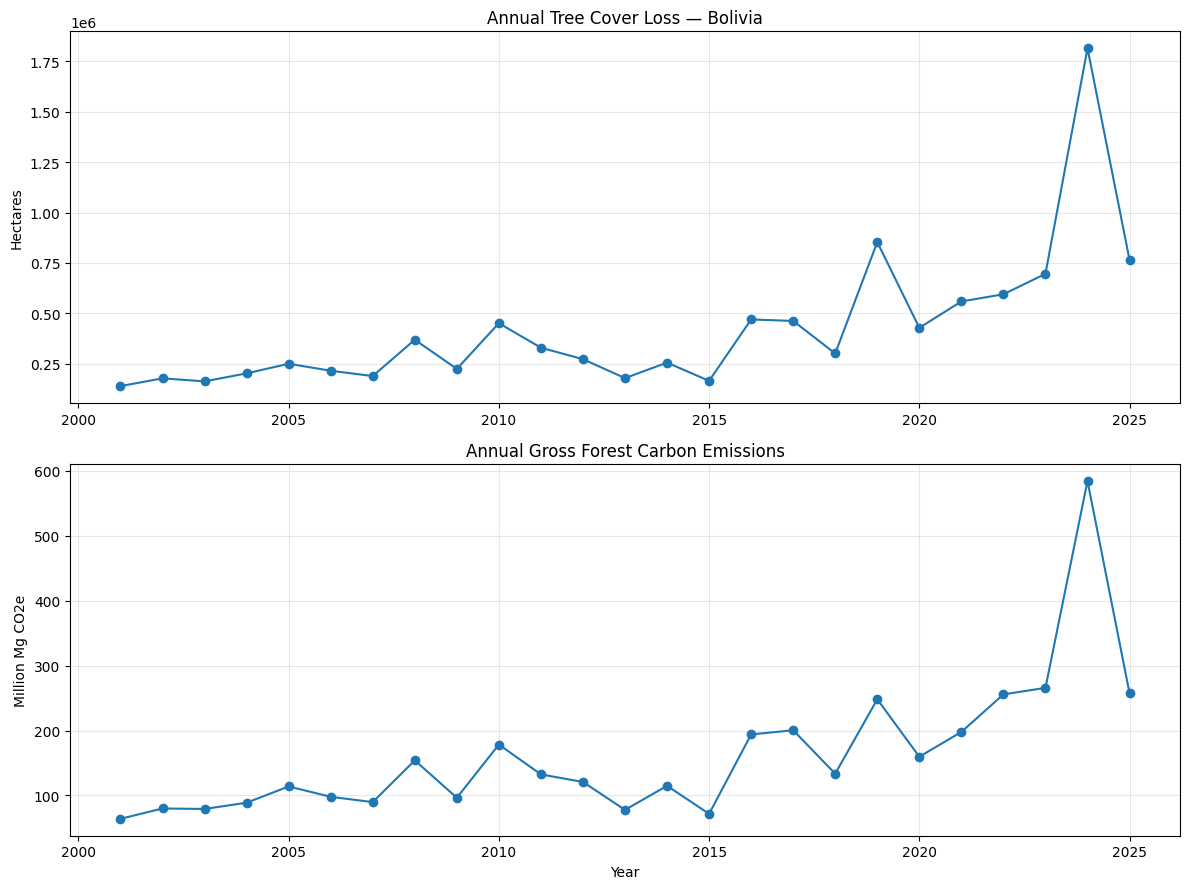

,year,tree_loss_ha,carbon_emissions
0,2001,140211,63976180
1,2002,178695,79935018
2,2003,163715,79181611
3,2004,203310,88773778
4,2005,250869,113838761
5,2006,216342,97877690
6,2007,189943,89715005
7,2008,369892,154027789
8,2009,225344,96418050
9,2010,451725,178413530


Highest tree cover loss year: 2024
Highest carbon emissions year: 2024


In [23]:

carbon_emissions_col = (
    "gfw_forest_carbon_gross_emissions__Mg_CO2e"
)

annual_trends = (
    master.groupby("year", as_index=False)
    .agg(
        tree_loss_ha=("tree_loss_ha", "sum"),
        carbon_emissions=(carbon_emissions_col, "sum")
    )
    .sort_values("year")
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

axes[0].plot(
    annual_trends["year"],
    annual_trends["tree_loss_ha"],
    marker="o"
)
axes[0].set_title("Annual Tree Cover Loss — Bolivia")
axes[0].set_ylabel("Hectares")
axes[0].grid(alpha=0.3)

axes[1].plot(
    annual_trends["year"],
    annual_trends["carbon_emissions"] / 1e6,
    marker="o"
)
axes[1].set_title("Annual Gross Forest Carbon Emissions")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Million Mg CO2e")
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_path / "03_annual_trends.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

display(annual_trends)

print(
    "Highest tree cover loss year:",
    annual_trends.loc[
        annual_trends["tree_loss_ha"].idxmax(), "year"
    ]
)

print(
    "Highest carbon emissions year:",
    annual_trends.loc[
        annual_trends["carbon_emissions"].idxmax(), "year"
    ]
)


### 3.4. Robust Regression with Log-Transformed Variables

**Objective:** Reevaluate the relationship between forest cover extent and annual carbon emissions using log-transformed variables.

**Methodology:**

The analysis compares Ordinary Least Squares (OLS) and RANSAC regression using 2024 observations at a 30% canopy density threshold.

Both variables are transformed using:

$$
X'=\ln(1+X)
$$

$$
Y'=\ln(1+Y)
$$

The logarithmic transformation reduces scale differences and the influence of extremely large values.

**Regression equation:**

$$
\hat{Y}'=\beta_0+\beta_1X'
$$

RANSAC uses a residual threshold of 1.5 in transformed units, a 50% minimum sample fraction and a fixed random seed.

**Important considerations:**

- RANSAC classifications depend on the selected parameters.
- Outliers are not automatically considered data errors.
- The analysis evaluates regression sensitivity, not causality.
- Neither model is used to modify the original dataset.

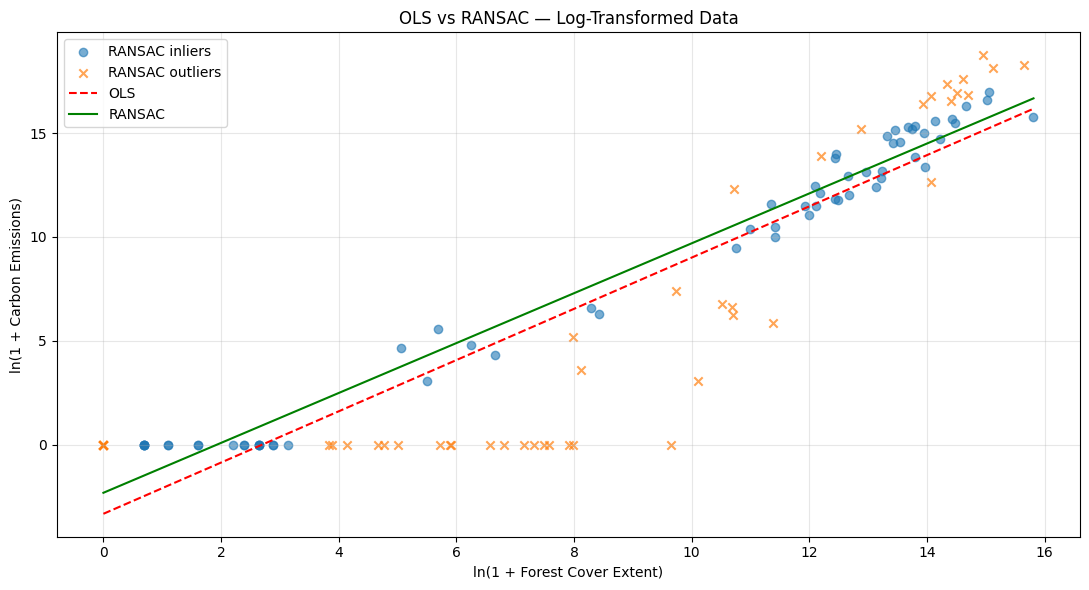

Observations: 112
OLS slope: 1.2332
RANSAC slope: 1.2008
Inliers: 64
Outliers: 48


In [24]:

from sklearn.linear_model import LinearRegression, RANSACRegressor

carbon_eda = datasets["carbon"].loc[
    (datasets["carbon"]["year"] == 2024) &
    (datasets["carbon"]["threshold"] == 30)
].copy()

carbon_eda["log_extent"] = np.log1p(
    carbon_eda["umd_tree_cover_extent_2000__ha"]
)

carbon_eda["log_emissions"] = np.log1p(
    carbon_eda["gfw_forest_carbon_gross_emissions__Mg_CO2e"]
)

X = carbon_eda[["log_extent"]]
y = carbon_eda["log_emissions"]

ols_log = LinearRegression().fit(X, y)

ransac_log = RANSACRegressor(
    estimator=LinearRegression(),
    min_samples=0.5,
    residual_threshold=1.5,
    max_trials=1000,
    random_state=42
).fit(X, y)

inliers = ransac_log.inlier_mask_
outliers = ~inliers

x_line = pd.DataFrame({
    "log_extent": np.linspace(
        X["log_extent"].min(),
        X["log_extent"].max(),
        200
    )
})

plt.figure(figsize=(11, 6))

plt.scatter(
    X.loc[inliers, "log_extent"],
    y.loc[inliers],
    alpha=0.6,
    label="RANSAC inliers"
)

plt.scatter(
    X.loc[outliers, "log_extent"],
    y.loc[outliers],
    marker="x",
    alpha=0.7,
    label="RANSAC outliers"
)

plt.plot(
    x_line["log_extent"],
    ols_log.predict(x_line),
    "r--",
    label="OLS"
)

plt.plot(
    x_line["log_extent"],
    ransac_log.predict(x_line),
    "g-",
    label="RANSAC"
)

plt.xlabel("ln(1 + Forest Cover Extent)")
plt.ylabel("ln(1 + Carbon Emissions)")
plt.title("OLS vs RANSAC — Log-Transformed Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_path / "04_robust_regression_log.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Observations:", len(X))
print("OLS slope:", round(ols_log.coef_[0], 4))
print(
    "RANSAC slope:",
    round(ransac_log.estimator_.coef_[0], 4)
)
print("Inliers:", int(inliers.sum()))
print("Outliers:", int(outliers.sum()))


### 3.5. Statistical Outlier Audit Summary

**Objective:** Consolidate the IQR-based outlier detection results for all five original datasets.

**Mathematical formulas:**

$$
IQR=Q_3-Q_1
$$

$$
OutlierRate_{\%}=\frac{N_{outliers}}{N_{observations}}\times100
$$

**Methodology:** Summarize the number and proportion of statistical outliers detected in each dataset.

**Decision:** Preserve all original observations. Statistical flags are recorded for investigation and will not trigger automatic deletion, imputation or winsorization.

**Expected outcome:** An exportable outlier audit report for the final Data Quality documentation.

In [25]:
outlier_summary = iqr_report[
    ["Dataset", "Observations", "Outliers", "Outliers (%)"]
].copy()

outlier_summary = outlier_summary.sort_values(
    "Outliers (%)",
    ascending=False
)

display(outlier_summary)

reports_path = DATA_PATH / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

outlier_summary.to_csv(
    reports_path / "outlier_audit_v2.csv",
    index=False
)

print("Outlier audit report saved successfully.")

,Dataset,Observations,Outliers,Outliers (%)
0,carbon,2800,476,17.00
1,tree_cover,2800,473,16.89
2,drivers,8351,1298,15.54
4,primary_drivers,6506,944,14.51
3,primary_loss,1296,165,12.73


Outlier audit report saved successfully.


### 3.6. Forest Loss Drivers Analysis

**Objective:** Identify the main drivers associated with forest cover loss and primary forest loss in Bolivia.

**Methodology:**

The analysis aggregates driver-attributed forest loss by category over the common period 2002–2025, using a 30% canopy density threshold.

Two separate charts are generated for general tree cover loss drivers and primary forest loss drivers.

**Mathematical formulas:**

Total attributed loss by driver:

$$
L_d=\sum_{y=2002}^{2025}Loss_{d,y}
$$

Percentage contribution within each source:

$$
P_d=\frac{L_d}{\sum_j L_j}\times100
$$

**Data Quality Considerations:**

- Drivers represent attributed causes, not independently verified causal events.
- The two datasets have different geographic coverage.
- Percentages are calculated separately for each source.
- No statistical outliers are removed or modified.

**Expected outcome:** A comparative visualization and tables showing the distribution of driver-attributed loss across categories.

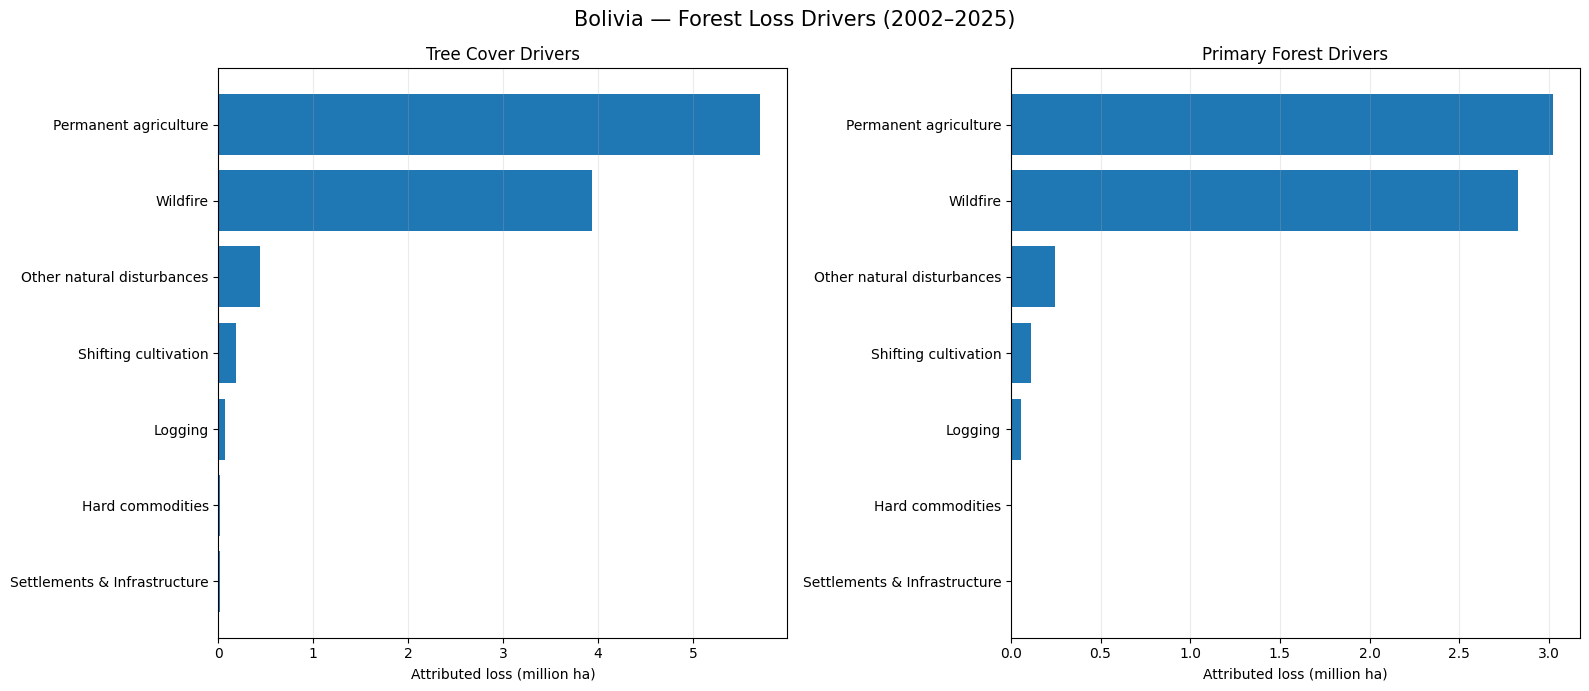


Tree Cover Drivers


,driver,loss_ha,share_pct
3,Permanent agriculture,5709314,55.00
6,Wildfire,3940824,37.96
2,Other natural disturbances,439571,4.23
5,Shifting cultivation,182716,1.76
1,Logging,72497,0.70
0,Hard commodities,18878,0.18
4,Settlements & Infrastructure,16534,0.16



Primary Forest Drivers


,driver,loss_ha,share_pct
3,Permanent agriculture,3022221,48.14
6,Wildfire,2827905,45.05
2,Other natural disturbances,248820,3.96
5,Shifting cultivation,113525,1.81
1,Logging,55870,0.89
0,Hard commodities,7761,0.12
4,Settlements & Infrastructure,1680,0.03


In [26]:

driver_datasets = {
    "Tree Cover Drivers": datasets["drivers"],
    "Primary Forest Drivers": datasets["primary_drivers"]
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

driver_reports = {}

for ax, (name, df) in zip(axes, driver_datasets.items()):

    filtered = df.loc[
        df["year"].between(2002, 2025)
        & df["threshold"].eq(30)
    ]

    summary = (
        filtered.groupby("driver", as_index=False)
        .agg(loss_ha=("tc_loss_ha", "sum"))
        .sort_values("loss_ha", ascending=False)
    )

    summary["share_pct"] = (
        summary["loss_ha"] / summary["loss_ha"].sum() * 100
    )

    driver_reports[name] = summary

    ax.barh(
        summary["driver"],
        summary["loss_ha"] / 1e6
    )

    ax.invert_yaxis()
    ax.set_title(name)
    ax.set_xlabel("Attributed loss (million ha)")
    ax.grid(axis="x", alpha=0.25)

plt.suptitle(
    "Bolivia — Forest Loss Drivers (2002–2025)",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    figures_path / "05_forest_loss_drivers.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

for name, summary in driver_reports.items():
    print(f"\n{name}")
    display(summary.round(2))


### 3.7. Consolidated Data Quality Report

**Objective:** Produce a reproducible report documenting the results, validation status, statistical anomalies and integration limitations of the V2 dataset.

**Methodology:**

Results from the existing validation, source coverage, outlier detection and reconciliation analyses are consolidated into a single Markdown report.

**Reconciliation formulas:**

$$
NetGap_{\%}=\frac{\sum Drivers-\sum TreeCover}{\sum TreeCover}\times100
$$

$$
AbsoluteGap_{\%}=\frac{\sum|Drivers_i-TreeCover_i|}{\sum TreeCover_i}\times100
$$

**Data Quality Policy:**

Missing measurements caused by differences in source coverage are preserved as null values. Statistical outliers are retained unless an actual data error can be demonstrated.

**Expected outcome:** A report documenting verified findings, unresolved discrepancies and the decisions made during data processing.

In [27]:

reports_path = DATA_PATH / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

tree_total = matched["tree_loss_ha"].sum()
drivers_total = matched["drivers_sum_ha"].sum()

net_gap = (drivers_total - tree_total) / tree_total * 100

absolute_gap = (
    matched["difference_ha"].abs().sum()
    / tree_total * 100
)

passed = int(validation_report["Passed"].sum())
total_checks = len(validation_report)

report_content = f"""# Bolivia Deforestation — Data Quality Report V2

## 1. Project Scope

- Source: Global Nature Watch
- Geographic scope: Bolivia, Subnational 2
- Integrated period: 2001–2025
- Primary forest data: 2002–2025
- Integrated canopy threshold: 30%
- Original datasets: {len(datasets)}
- Integrated observations: {len(master):,}
- Integrated columns: {master.shape[1]}

## 2. Structural Validation

- Passed checks: {passed}/{total_checks}
- Duplicate composite keys: {master.duplicated(keys).sum()}
- Original source records preserved: Yes

{validation_report.to_markdown(index=False)}

## 3. Source Coverage

{coverage_report.to_markdown(index=False)}

Missing source observations are preserved as null values.

## 4. Statistical Outlier Detection

Method: Interquartile Range (IQR), multiplier 1.5.

{outlier_summary.to_markdown(index=False)}

Outliers were flagged but not automatically removed.

## 5. Cross-Dataset Reconciliation

- Matched observations: {len(matched):,}
- Tree Cover total: {tree_total:,.0f} ha
- Drivers total: {drivers_total:,.0f} ha
- Net relative difference: {net_gap:.2f}%
- Absolute reconciliation gap: {absolute_gap:.2f}%

Differences do not automatically indicate source errors.

## 6. Processing Decisions

| Issue | Decision |
|---|---|
| Missing primary forest data in 2001 | Preserve null |
| Unmatched source observations | Preserve null |
| IQR statistical outliers | Retain and document |
| Tree Cover vs Drivers discrepancies | Preserve original values |
| Canopy threshold differences | Integrate using threshold 30 |
| Driver categories | Preserve in original detailed datasets |

## 7. Limitations

- Statistical outliers are not confirmed data errors.
- Structural validation does not establish measurement accuracy.
- Coverage differs between original sources.
- The integrated dataset is restricted to threshold 30.
- Driver classifications and scientific measurements are not independently verified.
- Reconciliation results describe matched observations only.

## 8. Conclusion

The project demonstrates data profiling, integrity validation,
multi-source integration, statistical anomaly detection,
reconciliation and reproducible analytical processing.

No unsupported numerical corrections were applied.
"""

report_file = reports_path / "DATA_QUALITY_REPORT_V2.md"
report_file.write_text(report_content, encoding="utf-8")

print("Report generated successfully.")
print("Location:", report_file)
print(f"Validations: {passed}/{total_checks}")
print(f"Net reconciliation gap: {net_gap:.2f}%")
print(f"Absolute reconciliation gap: {absolute_gap:.2f}%")


Report generated successfully.
Location: /content/drive/MyDrive/DatosDeforestacion/reports/DATA_QUALITY_REPORT_V2.md
Validations: 10/10
Net reconciliation gap: -0.23%
Absolute reconciliation gap: 0.23%


### 3.8. Primary Forest Loss Reconciliation

**Objective:** Evaluate numerical consistency between primary forest loss and the sum of driver-attributed primary forest losses.

**Methodology:**

Only observations with available measurements in both sources are compared. The reconciliation uses the integrated dataset at a 30% canopy density threshold.

**Mathematical formulas:**

Absolute difference:

$$
D_i = Drivers_i - PrimaryLoss_i
$$

Net relative difference:

$$
NetGap_{\%}=\frac{\sum Drivers-\sum PrimaryLoss}{\sum PrimaryLoss}\times100
$$

Absolute reconciliation gap:

$$
AbsoluteGap_{\%}=\frac{\sum |D_i|}{\sum PrimaryLoss_i}\times100
$$

**Data Quality Policy:**

Missing observations are excluded from numerical reconciliation but retained in the integrated dataset. Numerical discrepancies are documented without automatically modifying original measurements.

**Expected outcome:** A reconciliation report identifying matched records, unmatched records and numerical differences.

In [28]:

primary_matched = master.loc[
    master["has_primary_loss"] &
    master["has_primary_drivers"]
].copy()

primary_matched["difference_ha"] = (
    primary_matched["primary_drivers_sum_ha"]
    - primary_matched["primary_tc_loss_ha"]
)

primary_tree_total = primary_matched["primary_tc_loss_ha"].sum()
primary_drivers_total = primary_matched["primary_drivers_sum_ha"].sum()

primary_net_gap = (
    (primary_drivers_total - primary_tree_total)
    / primary_tree_total * 100
)

primary_absolute_gap = (
    primary_matched["difference_ha"].abs().sum()
    / primary_tree_total * 100
)

primary_reconciliation = pd.DataFrame({
    "Metric": [
        "Matched observations",
        "Only Primary Loss",
        "Only Primary Drivers",
        "Exact numerical matches",
        "Numerical differences",
        "Net relative gap (%)",
        "Absolute reconciliation gap (%)"
    ],
    "Value": [
        len(primary_matched),
        int((
            master["has_primary_loss"] &
            ~master["has_primary_drivers"]
        ).sum()),
        int((
            ~master["has_primary_loss"] &
            master["has_primary_drivers"]
        ).sum()),
        int((primary_matched["difference_ha"] == 0).sum()),
        int((primary_matched["difference_ha"] != 0).sum()),
        round(primary_net_gap, 4),
        round(primary_absolute_gap, 4)
    ]
})

display(primary_reconciliation)

primary_reconciliation.to_csv(
    reports_path / "primary_reconciliation_v2.csv",
    index=False
)


,Metric,Value
0,Matched observations,1272.0000
1,Only Primary Loss,24.0000
2,Only Primary Drivers,0.0000
3,Exact numerical matches,157.0000
4,Numerical differences,1115.0000
5,Net relative gap (%),-0.1796
6,Absolute reconciliation gap (%),0.1802


### 3.9. Final Dataset Verification and Export

**Objective:** Verify that the final integrated dataset can be reproduced from the original sources and exported without structural inconsistencies.

**Validation requirements:**

$$
N_{final}=N_{base}
$$

$$
N_{duplicate\ keys}=0
$$

The reconstructed dataset must contain the same columns, values and data types as the validated reference.

**Processing decisions:**

- Preserve the five original CSV files.
- Retain statistical outliers without automatic modification.
- Preserve structurally missing measurements.
- Maintain source availability indicators.
- Export the integrated analytical dataset separately from the raw inputs.

**Expected outcome:** A verified dataset and a final validation summary.

Passing structural tests does not imply that all source measurements are error-free.

In [29]:

rebuilt_final = build_dataset_from_csv(DATA_PATH)

pd.testing.assert_frame_equal(
    rebuilt_final.reset_index(drop=True),
    master.reset_index(drop=True)
)

final_checks = {
    "Reproducible integration": True,
    "Row count preserved": (
        len(rebuilt_final) == len(
            datasets["tree_cover"].query("threshold == 30")
        )
    ),
    "Unique composite keys": (
        not rebuilt_final.duplicated(keys).any()
    ),
    "Valid years": (
        rebuilt_final["year"].between(2001, 2025).all()
    ),
    "Valid threshold": (
        rebuilt_final["threshold"].eq(30).all()
    ),
    "Missing primary loss in 2001": (
        rebuilt_final.loc[
            rebuilt_final["year"] == 2001,
            "primary_tc_loss_ha"
        ].isna().all()
    )
}

final_validation = pd.DataFrame([
    {"Check": name, "Passed": bool(passed)}
    for name, passed in final_checks.items()
])

display(final_validation)

if not final_validation["Passed"].all():
    raise ValueError("Final validation failed")

processed_path = DATA_PATH / "processed"
processed_path.mkdir(parents=True, exist_ok=True)

final_file = (
    processed_path /
    "bolivia_deforestation_integrated_v2.csv"
)

rebuilt_final.to_csv(final_file, index=False)

final_validation.to_csv(
    reports_path / "final_validation_v2.csv",
    index=False
)

print("FINAL VALIDATION: PASSED")
print("Dataset:", rebuilt_final.shape)
print("Saved:", final_file)


,Check,Passed
0,Reproducible integration,True
1,Row count preserved,True
2,Unique composite keys,True
3,Valid years,True
4,Valid threshold,True
5,Missing primary loss in 2001,True


FINAL VALIDATION: PASSED
Dataset: (2800, 23)
Saved: /content/drive/MyDrive/DatosDeforestacion/processed/bolivia_deforestation_integrated_v2.csv


### 4.1. Standalone Python Integration Module

**Objective:** Export the validated integration logic into an independent Python module.

**Methodology:**

The module will read the five original CSV files, aggregate driver-attributed forest losses, perform validated joins and preserve source availability indicators.

**Validation criteria:**

$$
N_{module}=N_{reference}=2800
$$

The resulting dataset must match the previously validated notebook output in structure, values and data types.

**Expected outcome:** A reusable `src/integration.py` file and a successful reproducibility test.

**Data integrity:** Original CSV files remain unchanged.

In [31]:

from pathlib import Path
import importlib.util
import pandas as pd

src_path = DATA_PATH / "src"
src_path.mkdir(parents=True, exist_ok=True)

module_path = src_path / "integration.py"

module_code = '''
from pathlib import Path
import pandas as pd

FILES = {
    "carbon": "BOL - Subnational 2 carbon data.csv",
    "tree_cover": "BOL - Subnational 2 tree cover loss.csv",
    "drivers": "BOL - Subnational 2 drivers.csv",
    "primary_drivers": "BOL - Subnational 2 primary drivers.csv",
    "primary_loss": "BOL - Subnational 2 primary loss.csv"
}

KEYS = [
    "country", "subnational1", "subnational2",
    "threshold", "year"
]


def aggregate_drivers(df, output_column):
    """Aggregate driver-attributed forest loss."""
    return (
        df.groupby(KEYS, as_index=False)["tc_loss_ha"]
        .sum()
        .rename(columns={"tc_loss_ha": output_column})
    )


def build_dataset(data_path):
    """Build and validate the integrated forest dataset."""
    data_path = Path(data_path)

    raw = {
        name: pd.read_csv(data_path / filename)
        for name, filename in FILES.items()
    }

    base = (
        raw["tree_cover"]
        .loc[lambda df: df["threshold"].eq(30)]
        .rename(columns={"tc_loss_ha": "tree_loss_ha"})
        .copy()
    )

    sources = {
        "carbon": raw["carbon"].query("threshold == 30").copy(),
        "primary_loss": raw["primary_loss"].copy(),
        "drivers": aggregate_drivers(
            raw["drivers"], "drivers_sum_ha"
        ),
        "primary_drivers": aggregate_drivers(
            raw["primary_drivers"], "primary_drivers_sum_ha"
        )
    }

    result = base

    for name, source in sources.items():
        result = result.merge(
            source,
            on=KEYS,
            how="left",
            validate="one_to_one",
            indicator=True
        )

        result[f"has_{name}"] = result.pop("_merge").eq("both")

    if len(result) != len(base):
        raise ValueError("Unexpected row multiplication")

    if result.duplicated(KEYS).any():
        raise ValueError("Duplicate composite keys")

    if not result.loc[
        result["year"].eq(2001), "primary_tc_loss_ha"
    ].isna().all():
        raise ValueError("Invalid primary loss coverage")

    return result
'''

module_path.write_text(module_code, encoding="utf-8")

spec = importlib.util.spec_from_file_location(
    "forest_integration",
    module_path
)

integration_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(integration_module)

module_result = integration_module.build_dataset(DATA_PATH)

pd.testing.assert_frame_equal(
    module_result.reset_index(drop=True),
    master.reset_index(drop=True)
)

print("MODULE CREATED SUCCESSFULLY")
print("STANDALONE MODULE: PASSED")
print("Dataset:", module_result.shape)
print("Saved:", module_path)


MODULE CREATED SUCCESSFULLY
STANDALONE MODULE: PASSED
Dataset: (2800, 23)
Saved: /content/drive/MyDrive/DatosDeforestacion/src/integration.py


### 4.2. Final Data Quality Report Update

**Objective:** Complete the consolidated data quality report with the Primary Forest Loss reconciliation results.

**Methodology:** Incorporate matched observations, numerical differences, and reconciliation metrics from the previously validated analysis.

**Mathematical formulas:**

Net relative difference:

$$
NetGap_{\%}=\frac{\sum Drivers-\sum PrimaryLoss}{\sum PrimaryLoss}\times100
$$

Absolute reconciliation gap:

$$
AbsoluteGap_{\%}=\frac{\sum|Drivers_i-PrimaryLoss_i|}{\sum PrimaryLoss_i}\times100
$$

**Expected outcome:** An updated Markdown report documenting the integration results, anomaly detection findings, reconciliation differences, and processing decisions.

No original data will be modified.

In [32]:

report_file = reports_path / "DATA_QUALITY_REPORT_V2.md"

section_title = "## 9. Primary Forest Reconciliation"

only_primary = int((
    master["has_primary_loss"] &
    ~master["has_primary_drivers"]
).sum())

exact_matches = int(
    (primary_matched["difference_ha"] == 0).sum()
)

different_values = int(
    (primary_matched["difference_ha"] != 0).sum()
)

section = f"""
{section_title}

- Matched observations: {len(primary_matched):,}
- Only Primary Loss: {only_primary:,}
- Exact numerical matches: {exact_matches:,}
- Numerical discrepancies: {different_values:,}
- Net relative gap: {primary_net_gap:.4f}%
- Absolute reconciliation gap: {primary_absolute_gap:.4f}%

### Processing Decision

Original values were preserved. Numerical discrepancies
are documented and require methodological investigation.

No automatic corrections or outlier removal were applied.
"""

content = report_file.read_text(encoding="utf-8")

if section_title in content:
    content = content.split(section_title)[0].rstrip()

report_file.write_text(
    content.rstrip() + "\n\n" + section.strip() + "\n",
    encoding="utf-8"
)

print("FINAL QUALITY REPORT: UPDATED")
print("File:", report_file)


FINAL QUALITY REPORT: UPDATED
File: /content/drive/MyDrive/DatosDeforestacion/reports/DATA_QUALITY_REPORT_V2.md


### 4.3. Automated Integration Testing

**Objective:** Implement automated tests to verify the reproducibility and structural integrity of the Python integration pipeline.

**Testing strategy:**

1. Verify that the integrated dataset contains the expected number of observations and columns.
2. Validate composite key uniqueness.
3. Confirm the supported temporal and canopy threshold ranges.
4. Verify the absence of primary forest measurements for 2001.
5. Validate the expected source matching counts.

**Mathematical conditions:**

$$
N_{rows}=2800
$$

$$
N_{duplicate\ keys}=0
$$

$$
N_{columns}=23
$$

**Expected outcome:** A reusable Python test module that can be executed independently from Google Colab.

These tests verify structural data contracts, not the scientific accuracy of the source measurements.

In [33]:

import subprocess
import sys
import textwrap

tests_path = DATA_PATH / "tests"
tests_path.mkdir(parents=True, exist_ok=True)

test_code = textwrap.dedent('''
import sys
import unittest
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))

from integration import build_dataset, KEYS


class TestForestIntegration(unittest.TestCase):

    @classmethod
    def setUpClass(cls):
        data_dir = (
            ROOT / "data" / "raw"
            if (ROOT / "data" / "raw").exists()
            else ROOT
        )
        cls.df = build_dataset(data_dir)

    def test_expected_shape(self):
        self.assertEqual(self.df.shape, (2800, 23))

    def test_unique_keys(self):
        self.assertEqual(
            int(self.df.duplicated(KEYS).sum()), 0
        )

    def test_years_and_threshold(self):
        self.assertTrue(
            self.df["year"].between(2001, 2025).all()
        )
        self.assertTrue(
            self.df["threshold"].eq(30).all()
        )

    def test_primary_loss_2001(self):
        values = self.df.loc[
            self.df["year"] == 2001,
            "primary_tc_loss_ha"
        ]
        self.assertTrue(values.isna().all())

    def test_source_coverage(self):
        expected = {
            "carbon": 2800,
            "primary_loss": 1296,
            "drivers": 1636,
            "primary_drivers": 1272
        }

        for name, count in expected.items():
            with self.subTest(source=name):
                self.assertEqual(
                    int(self.df[f"has_{name}"].sum()),
                    count
                )


if __name__ == "__main__":
    unittest.main()
''')

test_file = tests_path / "test_integration.py"
test_file.write_text(test_code, encoding="utf-8")

result = subprocess.run(
    [
        sys.executable, "-m", "unittest",
        "discover",
        "-s", str(tests_path),
        "-p", "test_*.py",
        "-v"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Automated tests failed")

print("AUTOMATED TESTS: PASSED")



test_expected_shape (test_integration.TestForestIntegration.test_expected_shape) ... ok
test_primary_loss_2001 (test_integration.TestForestIntegration.test_primary_loss_2001) ... ok
test_source_coverage (test_integration.TestForestIntegration.test_source_coverage) ... ok
test_unique_keys (test_integration.TestForestIntegration.test_unique_keys) ... ok
test_years_and_threshold (test_integration.TestForestIntegration.test_years_and_threshold) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.480s

OK

AUTOMATED TESTS: PASSED


## 5. GitHub Portfolio Preparation

### 5.1. Repository Structure and Documentation

**Objective:** Prepare a professional, reproducible GitHub repository containing the Python integration module, automated tests, exploratory analysis, visualizations and data quality reports.

**Methodology:**

- Organize project files into dedicated directories.
- Preserve the original project and source datasets.
- Generate an English README explaining the methodology and findings.
- Document dependencies and exclude local or unlicensed data files from public distribution.

**Expected outcome:** A structured repository ready for final review and GitHub publication.

**Scope:** This project demonstrates data profiling, quality validation, reconciliation, statistical anomaly detection and reproducible data integration. No unsupported corrections to source measurements were performed.

In [34]:

import shutil
from pathlib import Path
from importlib.metadata import version

repo = DATA_PATH / "github_project"

folders = [
    "src",
    "tests",
    "notebooks",
    "reports",
    "figures",
    "data/raw"
]

for folder in folders:
    (repo / folder).mkdir(parents=True, exist_ok=True)

required_files = {
    "src/integration.py": DATA_PATH / "src/integration.py",
    "tests/test_integration.py": DATA_PATH / "tests/test_integration.py"
}

for destination, source in required_files.items():
    if not source.is_file():
        raise FileNotFoundError(source)
    shutil.copy2(source, repo / destination)

for folder, extension in [
    ("reports", "*"),
    ("figures", "*.png")
]:
    for source in (DATA_PATH / folder).glob(extension):
        if source.is_file():
            shutil.copy2(source, repo / folder / source.name)

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "scikit-learn",
    "tabulate"
]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
)

(repo / "requirements.txt").write_text(
    requirements + "\n", encoding="utf-8"
)

gitignore = """
__pycache__/
.ipynb_checkpoints/
*.py[cod]
.env
.venv/
data/raw/*.csv
data/processed/
*.zip
"""

(repo / ".gitignore").write_text(
    gitignore.strip() + "\n", encoding="utf-8"
)

(repo / "data/raw/README.md").write_text(
    "Place the five original Bolivia CSV files here before "
    "running the pipeline or integration tests.\n"
    "Source: https://globalnaturewatch.org/dashboards/country/BOL/\n",
    encoding="utf-8"
)

readme = """# Bolivia Forest Data Quality & Reconciliation

A reproducible Python project for auditing, integrating and
analyzing forest loss and carbon data from Bolivia (2001–2025).

## Project Overview

This project demonstrates professional data quality practices
using five environmental datasets from Global Nature Watch.

**Technologies:** Python, pandas, NumPy, Matplotlib,
scikit-learn, Google Colab and unittest.

## Data Sources

- Subnational 2 Tree Cover Loss
- Subnational 2 Carbon Data
- Subnational 2 Drivers
- Subnational 2 Primary Loss
- Subnational 2 Primary Drivers

Source: https://globalnaturewatch.org/dashboards/country/BOL/

## Methodology

1. Data profiling and structural quality audits
2. Geographic, temporal and threshold coverage validation
3. Composite key validation
4. Multi-source integration at the 30% canopy threshold
5. Cross-dataset numerical reconciliation
6. IQR-based statistical outlier detection
7. OLS and RANSAC sensitivity analysis
8. Exploratory analysis and automated validation

## Key Results

| Metric | Result |
|---|---|
| Original datasets | 5 |
| Total original source rows | 46,953 |
| Integrated dataset | 2,800 rows, 23 columns |
| Structural integration checks | 10/10 passed |
| Final validation checks | 6/6 passed |
| Automated integration tests | 5 passed |
| Tree Cover / Drivers matching coverage | 58.43% |
| Tree Cover / Drivers net reconciliation gap | -0.23% |

## Data Quality Decisions

- Original measurements were preserved.
- Structural missing values were not automatically imputed.
- Statistical outliers were flagged rather than deleted.
- Numerical discrepancies were retained and documented.
- Detailed driver categories remain available in source datasets.

## Project Structure

- `src/` — Reusable Python integration code
- `tests/` — Automated integration tests
- `notebooks/` — Documented Google Colab analysis
- `reports/` — Quality and reconciliation reports
- `figures/` — Analytical visualizations
- `data/raw/` — Local source data location

## Installation

Install Python dependencies:

```bash
pip install -r requirements.txt
```

Place the five original CSV files in `data/raw/`.

Run integration tests:

```bash
python -m unittest discover -s tests -v
```

Example integration:

```python
from pathlib import Path
from src.integration import build_dataset

df = build_dataset(Path("data/raw"))
print(df.shape)
```

## Limitations

The integrated dataset uses a 30% canopy density threshold.
Source coverage varies by geography and time period.

Statistical outliers are not necessarily measurement errors.
Reconciliation metrics are not overall data quality scores.
Tree cover loss does not always represent permanent deforestation.

## Data Attribution

Data source: Global Nature Watch / World Resources Institute.
Dataset-specific citations and redistribution permissions
should be verified before publishing source CSV files.

## Portfolio Purpose

Demonstrates reproducible data preparation, data quality
auditing, multi-source reconciliation and analytical reporting.
"""

(repo / "README.md").write_text(
    readme, encoding="utf-8"
)

print("GITHUB REPOSITORY STRUCTURE: CREATED")
print("Location:", repo)
print("README, requirements and .gitignore generated.")


GITHUB REPOSITORY STRUCTURE: CREATED
Location: /content/drive/MyDrive/DatosDeforestacion/github_project
README, requirements and .gitignore generated.


### 5.2. Repository Content Verification

**Objective:** Verify that the GitHub-ready project contains the required source code, automated tests, reports, figures and documentation.

**Methodology:** Inspect the generated directory structure and identify missing deliverables before publication.

**Expected outcome:** A complete file inventory and confirmation that the original CSV files have not been copied into the public repository.

In [35]:

required = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "src/integration.py",
    "tests/test_integration.py",
    "reports/DATA_QUALITY_REPORT_V2.md"
]

print("REPOSITORY CHECK\n")

for filename in required:
    exists = (repo / filename).is_file()
    status = "OK" if exists else "MISSING"
    print(f"[{status}] {filename}")

figures = list((repo / "figures").glob("*.png"))
notebooks = list((repo / "notebooks").glob("*.ipynb"))
raw_csv = list((repo / "data/raw").glob("*.csv"))

print(f"\nFigures: {len(figures)}")
print(f"Notebooks: {len(notebooks)}")
print(f"Raw CSV files: {len(raw_csv)}")

if raw_csv:
    raise ValueError("Raw CSV files found in public repository")

print("\nRepository directory:")
print(repo)


REPOSITORY CHECK

[OK] README.md
[OK] requirements.txt
[OK] .gitignore
[OK] src/integration.py
[OK] tests/test_integration.py
[OK] reports/DATA_QUALITY_REPORT_V2.md

Figures: 5
Notebooks: 0
Raw CSV files: 0

Repository directory:
/content/drive/MyDrive/DatosDeforestacion/github_project


### 4.4. Before and After Data Quality Assessment

**Objective:** Document and compare the characteristics of the original datasets and the integrated analytical dataset.

**Methodology:**

The assessment measures:

- Number of records and columns.
- Missing values.
- Duplicate rows.
- Preservation of original Tree Cover measurements.
- Processing decisions applied during integration.

**Mathematical formulas**

Missing value rate:

$$
MissingRate_{\%}=\frac{N_{missing\ cells}}{N_{total\ cells}}\times100
$$

Duplicate row rate:

$$
DuplicateRate_{\%}=\frac{N_{duplicate\ rows}}{N_{rows}}\times100
$$

**Important methodological distinction:**

The original datasets and integrated dataset have different structures and granularities. Their row counts and missing-value rates cannot be interpreted as direct improvements or reductions in data quality.

Missing measurements introduced by unmatched joins represent differences in source coverage rather than necessarily incorrect data.

**Expected outcome:** A transparent Before and After report demonstrating actual processing decisions and verified structural changes without claiming unsupported quality improvements.

In [36]:

import pandas as pd

quality_comparison = []

for name, df in datasets.items():
    quality_comparison.append({
        "Stage": "BEFORE",
        "Dataset": name,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Missing values": int(df.isna().sum().sum()),
        "Duplicate rows": int(df.duplicated().sum())
    })

quality_comparison.append({
    "Stage": "AFTER",
    "Dataset": "integrated_threshold30",
    "Rows": len(master),
    "Columns": master.shape[1],
    "Missing values": int(master.isna().sum().sum()),
    "Duplicate rows": int(master.duplicated().sum())
})

comparison_report = pd.DataFrame(quality_comparison)

display(comparison_report)

base_columns = keys + [
    "area_ha",
    "extent_2000_ha",
    "extent_2010_ha",
    "tree_loss_ha"
]

original_base = (
    datasets["tree_cover"]
    .loc[lambda df: df["threshold"].eq(30)]
    .rename(columns={"tc_loss_ha": "tree_loss_ha"})
    [base_columns]
    .sort_values(keys)
    .reset_index(drop=True)
)

integrated_base = (
    master[base_columns]
    .sort_values(keys)
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    original_base,
    integrated_base
)

decisions = pd.DataFrame([
    {
        "Finding": "Different source coverage",
        "Action": "Left joins with availability flags",
        "Original values modified": "No"
    },
    {
        "Finding": "Different canopy thresholds",
        "Action": "Select threshold 30 for integration",
        "Original values modified": "No"
    },
    {
        "Finding": "Missing source matches",
        "Action": "Preserve NaN and document coverage",
        "Original values modified": "No"
    },
    {
        "Finding": "Statistical outliers",
        "Action": "Flag and retain observations",
        "Original values modified": "No"
    },
    {
        "Finding": "Driver-level observations",
        "Action": "Aggregate by geographic unit and year",
        "Original values modified": "No"
    }
])

display(decisions)

comparison_report.to_csv(
    reports_path / "before_after_quality_v2.csv",
    index=False
)

decisions.to_csv(
    reports_path / "processing_decisions_v2.csv",
    index=False
)

print("SOURCE VALUE PRESERVATION: PASSED")
print("BEFORE/AFTER REPORT: SAVED")


,Stage,Dataset,Rows,Columns,Missing values,Duplicate rows
0,BEFORE,carbon,8400,12,0,0
1,BEFORE,tree_cover,22400,9,0,0
2,BEFORE,drivers,8351,7,0,0
3,BEFORE,primary_drivers,6506,7,0,0
4,BEFORE,primary_loss,1296,6,0,0
5,AFTER,integrated_threshold30,2800,23,4196,0


,Finding,Action,Original values modified
0,Different source coverage,Left joins with availability flags,No
1,Different canopy thresholds,Select threshold 30 for integration,No
2,Missing source matches,Preserve NaN and document coverage,No
3,Statistical outliers,Flag and retain observations,No
4,Driver-level observations,Aggregate by geographic unit and year,No


SOURCE VALUE PRESERVATION: PASSED
BEFORE/AFTER REPORT: SAVED


### 5.1. Before vs. After — Data Integration Quality

**Objective:** Visualize the original data sources and the coverage achieved after integration into a validated analytical dataset.

**Before Integration:**

Five independent datasets containing 46,953 source records in total, with different temporal, geographic and measurement coverage.

**After Integration:**

A unified analytical dataset containing 2,800 observations and 23 columns at the 30% canopy density threshold.

**Mathematical formulas:**

Source matching coverage:

$$
Coverage_s=\frac{N_{matched,s}}{N_{base}}\times100
$$

Unmatched observations:

$$
N_{unmatched,s}=N_{base}-N_{matched,s}
$$

For this integration, the number of missing cells introduced by unmatched joins is:

$$
N_{missing}=1504+1164+1528=4196
$$

**Interpretation:**

Missing values introduced during integration represent differences in source coverage, not necessarily data quality errors.

The original datasets have different granularities. Therefore, comparing 46,953 source records with 2,800 integrated records does not represent a reduction in erroneous observations.

**Expected outcome:** A professional visualization suitable for documenting the original sources, integration coverage and resulting analytical dataset.

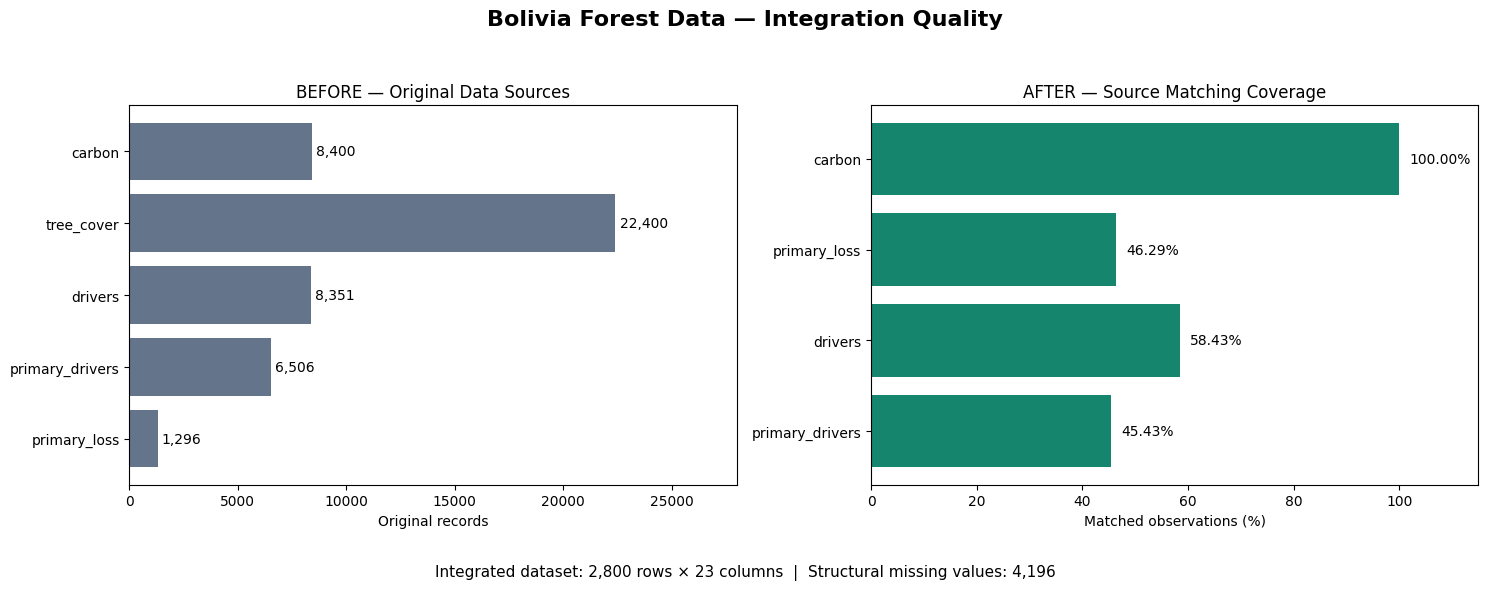

BEFORE/AFTER VISUALIZATION: SAVED
Structural missing values: 4196
Figure: /content/drive/MyDrive/DatosDeforestacion/figures/06_before_after_integration.png


In [37]:

import matplotlib.pyplot as plt
import numpy as np

raw_counts = {
    name: len(df)
    for name, df in datasets.items()
}

sources = [
    "carbon",
    "primary_loss",
    "drivers",
    "primary_drivers"
]

coverage = [
    master[f"has_{name}"].mean() * 100
    for name in sources
]

unmatched_counts = {
    name: int((~master[f"has_{name}"]).sum())
    for name in sources
}

introduced_missing = sum(unmatched_counts.values())
actual_missing = int(master.isna().sum().sum())

assert introduced_missing == actual_missing, (
    "Unexpected missing values require investigation"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

raw_names = list(raw_counts.keys())
raw_values = list(raw_counts.values())

axes[0].barh(raw_names, raw_values, color="#64748b")
axes[0].invert_yaxis()
axes[0].set_title("BEFORE — Original Data Sources")
axes[0].set_xlabel("Original records")

for i, value in enumerate(raw_values):
    axes[0].text(
        value + 200, i, f"{value:,}",
        va="center", fontsize=10
    )

axes[0].set_xlim(0, max(raw_values) * 1.25)

axes[1].barh(sources, coverage, color="#16856d")
axes[1].invert_yaxis()
axes[1].set_title("AFTER — Source Matching Coverage")
axes[1].set_xlabel("Matched observations (%)")
axes[1].set_xlim(0, 115)

for i, value in enumerate(coverage):
    axes[1].text(
        value + 2, i, f"{value:.2f}%",
        va="center", fontsize=10
    )

fig.suptitle(
    "Bolivia Forest Data — Integration Quality",
    fontsize=16, fontweight="bold"
)

fig.text(
    0.5, 0.035,
    f"Integrated dataset: {len(master):,} rows × {master.shape[1]} columns"
    f"  |  Structural missing values: {actual_missing:,}",
    ha="center", fontsize=11
)

fig.tight_layout(rect=[0, 0.09, 1, 0.94])

output_figure = figures_path / "06_before_after_integration.png"

fig.savefig(
    output_figure,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("BEFORE/AFTER VISUALIZATION: SAVED")
print("Structural missing values:", actual_missing)
print("Figure:", output_figure)


### 5.2. GitHub Repository Consolidation

**Objective:** Consolidate the validated source code, analytical figures, automated tests and Data Quality reports into a structured project directory.

**Methodology:**

- Copy the latest Python modules and test files.
- Synchronize Data Quality reports and analytical visualizations.
- Verify the presence of required publication files.
- Preserve all original data sources.

**Expected outcome:** A consolidated repository directory containing the latest project deliverables.

**Data Integrity:** Original files are not overwritten or modified. Public distribution of raw data will remain restricted until licensing conditions are verified.

In [38]:

from pathlib import Path
import shutil
import pandas as pd

repo = DATA_PATH / "github_project"

folders = ["src", "tests", "reports", "figures", "notebooks", "data/raw"]

for folder in folders:
    (repo / folder).mkdir(parents=True, exist_ok=True)

files_to_copy = {
    "src/integration.py": DATA_PATH / "src/integration.py",
    "tests/test_integration.py": DATA_PATH / "tests/test_integration.py"
}

for destination, source in files_to_copy.items():
    if not source.is_file():
        raise FileNotFoundError(source)

    shutil.copy2(source, repo / destination)

for folder, pattern in [
    ("reports", "*"),
    ("figures", "*.png")
]:
    for source in (DATA_PATH / folder).glob(pattern):
        if source.is_file():
            shutil.copy2(source, repo / folder / source.name)

required_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "src/integration.py",
    "tests/test_integration.py",
    "reports/DATA_QUALITY_REPORT_V2.md",
    "figures/06_before_after_integration.png"
]

results = []

for filename in required_files:
    results.append({
        "File": filename,
        "Status": (
            "READY" if (repo / filename).is_file()
            else "MISSING"
        )
    })

display(pd.DataFrame(results))

print("Figures:", len(list((repo / "figures").glob("*.png"))))
print("Notebooks:", len(list((repo / "notebooks").glob("*.ipynb"))))
print("Repository:", repo)


,File,Status
0,README.md,READY
1,requirements.txt,READY
2,.gitignore,READY
3,src/integration.py,READY
4,tests/test_integration.py,READY
5,reports/DATA_QUALITY_REPORT_V2.md,READY
6,figures/06_before_after_integration.png,READY


Figures: 6
Notebooks: 0
Repository: /content/drive/MyDrive/DatosDeforestacion/github_project
